# Earthquake Damage Prediction: Nepal, 2015
## From a building survey to a prioritised inspection list

On **25 April 2015** the Mw 7.8 Gorkha earthquake struck central Nepal. Surveyors later visited several hundred thousand buildings and recorded how each one performed. This notebook turns that survey into a model that answers one practical question for the government:

> *Given where a building stands and how it was built, how badly is it likely to be damaged in a shaking event like this one, and which buildings should be inspected or retrofitted first?*

**The target** `damage_grade` is **ordinal**: 1 (low damage) < 2 (medium) < 3 (near-complete destruction). A one-step error is less harmful than a two-step error, and that shapes the models and metrics we choose.

### How to read this notebook
Every code cell is preceded by a Markdown cell that answers four questions:
1. **What** does the next cell do?
2. **Why** do we do it (the decision, not just the action)?
3. **How** does the code work, in a few plain lines?
4. **What should I look for** in the output?

### Roadmap
| Chapter | Question it answers |
|---|---|
| 1 · Data quality | Can we trust the survey? |
| 2 · Exploration | What does damage look like in physical terms? |
| 3 & 4 · Features and split | What can we add from engineering knowledge, and how do we keep a fair test? |
| 5 · Pipeline | How do we prevent the model from cheating? |
| 6 · Metrics | How do we measure an *ordered* 3-class problem fairly? |
| 7 · Model comparison | Which model family suits ordered damage grades? |
| 8 · Tuning | Can settings and decision rules be improved? |
| 9 · Verdict | How good is it on buildings it never saw? |
| 10 · Drivers | Does it rely on physically sensible factors? |
| 11 · Deliverable | Which building IDs should the government act on first? |

In [6]:
# ════════════════════════════════════════════════════════════════════════
# 0 · SETUP: warnings off, configuration, colour theme
# ════════════════════════════════════════════════════════════════════════
import warnings, os, time
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

from pathlib import Path
import plotly.express as px
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:,.3f}".format)

# ---------- CONFIG (the only cell you normally edit) ----------
DATA_DIR   = Path(r"C:\Users\kanap\Downloads\PRCP-1015-EquakeDamagePred\Data")   # train_values.csv, train_labels.csv, (optional) test_values.csv
OUT_DIR    = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)                      # all CSVs land here
SEED       = 42
QUICK_MODE = False       # True = fast dry run on a subsample; False = full run
N_FOLDS    = 3 if QUICK_MODE else 5
MAX_ITER   = 150 if QUICK_MODE else 600     # boosting rounds (early stopping decides the real number)

# ---------- THEME: one colour language for the whole notebook ----------
DAMAGE_COLORS = {1: "#009E73", 2: "#E69F00", 3: "#D55E00"}     # teal-green = low, amber = medium, vermilion = severe
GRADE_NAMES   = {1: "1 · Low", 2: "2 · Medium", 3: "3 · Severe"}
PALETTE       = [DAMAGE_COLORS[g] for g in (1, 2, 3)]
RISK_SCALE    = PALETTE                                         # plotly continuous scale (low → severe)
ACCENT, INK, GRID = "#56606B", "#2B2B2B", "#E6E1D8"
RISK_CMAP = LinearSegmentedColormap.from_list("risk",      ["#FFF8E7", "#E69F00", "#D55E00", "#7A2E00"])
DIVERGING = LinearSegmentedColormap.from_list("diverging", ["#009E73", "#F7F3E8", "#D55E00"])

sns.set_theme(style="whitegrid", context="notebook", palette=PALETTE)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK,
                     "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False})
px.defaults.template = "plotly_white"
GRADE_LEGEND = [Patch(color=DAMAGE_COLORS[g], label=GRADE_NAMES[g]) for g in (1, 2, 3)]
print("Setup complete · quick mode:", QUICK_MODE)

Setup complete · quick mode: False


## Setup · configuration, colours and settings
**What:** one cell that holds every setting you might change, plus the colour theme.
**Why:** keeping settings in one place means the notebook can be re-run or re-pointed to another folder without hunting through the code. A single colour theme means the same colour always means the same thing.
**How:**
- `DATA_DIR` is where the CSVs live and `OUT_DIR` is where results are saved.
- `SEED = 42` fixes the random choices so results are reproducible.
- `QUICK_MODE` switches between a fast dry run and the full run.
- Colours carry meaning: **teal = low damage, amber = medium, vermilion = severe**, so a reader can spot risk at a glance.
- Warnings are switched off so the output stays readable.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df1 = pd.read_csv(r"C:\Users\kanap\Downloads\PRCP-1015-EquakeDamagePred\Data\train_values.csv")
df2 = pd.read_csv(r"C:\Users\kanap\Downloads\PRCP-1015-EquakeDamagePred\Data\train_labels.csv")
df = pd.merge(df1, df2, on="building_id", how="inner")

In [7]:
TEST_PATH = DATA_DIR / "test_values.csv"
test_df = pd.read_csv(TEST_PATH) if TEST_PATH.exists() else None      # the unseen buildings the government wants scored
print("Labelled buildings :", df.shape)
print("Unseen test file   :", None if test_df is None else test_df.shape)

# ── Decode the anonymised categories (your research, as lookup tables) ───
LABELS = {
    "land_surface_condition": {"t": "Flat", "n": "Moderate slope", "o": "Steep slope"},
    "foundation_type":        {"r": "Mud mortar stone/brick", "i": "Reinforced concrete", "u": "Timber", "w": "Bamboo", "h": "Other"},
    "roof_type":              {"n": "Light roof (bamboo/timber)", "q": "Heavy roof (bamboo/timber)", "x": "RCC / RB slab"},
    "ground_floor_type":      {"f": "Mud", "v": "RC", "x": "Timber planks", "m": "Brick/stone", "z": "Other"},
    "other_floor_type":       {"q": "None (single storey)", "s": "Timber planks", "x": "Timber/bamboo + mud", "j": "RCC / RB"},
    "position":               {"s": "Freestanding", "j": "Attached 1 side", "t": "Attached 2 sides", "o": "Attached 3+ sides"},
    "plan_configuration":     {"d": "Rectangular", "s": "Square", "u": "U-shaped", "q": "Multi-projected", "a": "L-shaped",
                               "c": "T-shaped", "o": "E-shaped", "m": "H-shaped", "n": "Courtyard", "f": "Other"},
    "legal_ownership_status": {},   # meaning not yet established, so codes are shown as-is
}

def decode(frame):
    """Human-readable copy for EDA charts only; models use the raw codes."""
    out = frame.copy()
    for col, mp in LABELS.items():
        out[col] = out[col].map(lambda v, mp=mp: f"{v} · {mp[v]}" if v in mp else str(v))
    return out

# ── Column groups used throughout ────────────────────────────────────────
ID, TARGET = "building_id", "damage_grade"
GEO_COLS  = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]
CAT_COLS  = list(LABELS.keys())
BIN_COLS  = [c for c in df.columns if c.startswith("has_")]
SUP       = [c for c in df.columns if c.startswith("has_superstructure_")]
SEC       = [c for c in df.columns if c.startswith("has_secondary_use_")]

# ── Audit ────────────────────────────────────────────────────────────────
audit = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique_values": df.nunique()})
display(audit.T)
feature_cols = [c for c in df.columns if c not in (ID, TARGET)]
print("\nDuplicate building_ids          :", df[ID].duplicated().sum())
print("Duplicate feature rows (any id) :", df.duplicated(subset=feature_cols).sum(), "(identical-looking buildings are legitimate, not errors)")

num_cols = ["count_floors_pre_eq", "age", "area_percentage", "height_percentage", "count_families"]
display(df[num_cols].describe().T)
print("\nLargest age values:\n", df["age"].value_counts().sort_index().tail(6).to_string())
print("\nBuildings with 0 families recorded:", (df["count_families"] == 0).sum())
if test_df is not None:
    for g in GEO_COLS[1:]:
        print(f"Share of test buildings whose {g} also appears in training: {test_df[g].isin(df[g]).mean():.1%}")

Labelled buildings : (260601, 40)
Unseen test file   : None


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
dtype,int64,int64,int64,int64,int64,int64,int64,int64,str,str,str,str,str,str,str,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,str,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
unique_values,260601,31,1414,11595,9,42,84,27,3,5,3,5,4,4,10,2,2,2,2,2,2,2,2,2,2,2,4,10,2,2,2,2,2,2,2,2,2,2,2,3



Duplicate building_ids          : 0
Duplicate feature rows (any id) : 16191 (identical-looking buildings are legitimate, not errors)


,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,"260,601.000",2.130,0.728,1.000,2.000,2.000,2.000,9.000
age,"260,601.000",26.535,73.566,0.000,10.000,15.000,30.000,995.000
area_percentage,"260,601.000",8.018,4.392,1.000,5.000,7.000,9.000,100.000
height_percentage,"260,601.000",5.434,1.918,2.000,4.000,5.000,6.000,32.000
count_families,"260,601.000",0.984,0.418,0.000,1.000,1.000,1.000,9.000



Largest age values:
 age
180       7
185       1
190       3
195       2
200     106
995    1390

Buildings with 0 families recorded: 20862


## Step 0 · First look at the data
**What:** import the core libraries, load the two survey files, join them, and print the first rows.
**Why:** a quick look confirms the files load, the join works, and the columns look as documented, before we invest in any analysis.
**How:** `train_values.csv` holds the building features and `train_labels.csv` holds the damage grade. They are joined on `building_id` with an inner join, so only buildings that have both a description and a label are kept.
**Look for:** 260,601 rows and 40 columns (39 features including the ID, plus the target).

*Note:* Cell 5 loads the data again, in the structured way used for the rest of the notebook. The repeat is harmless, and the cells above are just a first look.

# Chapter 1 · Can we trust the survey?
**What:** load the data, translate the anonymised letter codes into plain English, and audit data quality.
**Why:** a model is only as reliable as its data. The survey stored categories as single letters (`r`, `q`, `x`…), so we decode them using the data dictionary you researched. This makes every later chart readable by a non-technical reader. The audit then looks for missing values, duplicates and impossible values, because those silently distort results.
**How:**
- `LABELS` is a lookup table, and `decode()` makes a readable copy used **only for charts**. The models still use the raw codes.
- The audit table reports each column's type, missing count and number of unique values.
- Dedicated checks look at duplicate IDs, duplicate feature rows, the largest ages, and buildings with zero families.

## Q1.1 What did the audit show, and how do we fix it?
| Finding | Decision | Why |
|---|---|---|
| No missing values, no duplicate IDs | None needed | The survey is complete |
| 16,191 rows with identical features | Keep | Similar houses in the same village are real buildings, not errors |
| `age` = 995 (1,390 buildings) or 200 (106) | Set to missing + add an `age_unknown` flag | These are placeholders, not real ages, and would distort age patterns |
| `count_families = 0` (20,862 buildings, 8%) | Keep + add a flag | Vacant or non-residential buildings are valid records |
| Extreme area / height values | Keep | Tree models are not thrown off by extremes |

The next cell's `clean()` function makes these fixes. We leave missing ages as they are because gradient-boosted trees handle missing values themselves.

In [8]:
def clean(d):
    d = d.copy()
    d[BIN_COLS] = d[BIN_COLS].astype("int8")
    d["age_unknown"] = (d["age"] >= 200).astype("int8")          # 200 and 995 are placeholders
    d["age"] = d["age"].where(d["age"] < 200)                     # → NaN (trees handle it natively)
    d["no_family_recorded"] = (d["count_families"] == 0).astype("int8")
    for c in CAT_COLS:
        d[c] = d[c].astype(str)
    return d

df = clean(df)
test_clean = clean(test_df) if test_df is not None else None
print("Unknown ages set to NaN:", int(df["age"].isna().sum()))
eda = decode(df)       # readable copy used only for the charts in Chapter 2

Unknown ages set to NaN: 1496


# Chapter 2 · What does earthquake damage look like?
A seismologist reads this dataset through three physical ideas:
1. **Ground shaking is not uniform.** It weakens with distance from the rupture and is amplified by soft soil and steep terrain. Location columns are our only stand-in for this.
2. **A building is a mass on a spring.** Heavy roofs and tall, slender buildings attract larger forces, and weak, brittle materials (mud mortar, unreinforced masonry) cannot deform without cracking.
3. **Shape matters.** Irregular plans twist, attached buildings hammer each other, and weak ground floors collapse first.

Every chart below is a test of one of these ideas.

## Q2.1 How are the damage grades distributed?
**Why we ask:** the class balance decides how we evaluate and whether we need to rebalance.
**Finding:** grade 1 is 9.6%, grade 2 is 56.9% and grade 3 is 33.5%. Grade 2 dominates, but no class is tiny.
**Decision:** we do **not** resample. Micro-F1 is measured on the natural class mix, and over- or under-sampling usually lowers it. Instead we watch **per-grade recall** so the model cannot ignore the smaller grades.
**How the chart works:** a count plot with one bar per grade, coloured with the theme, and the percentage printed above each bar.

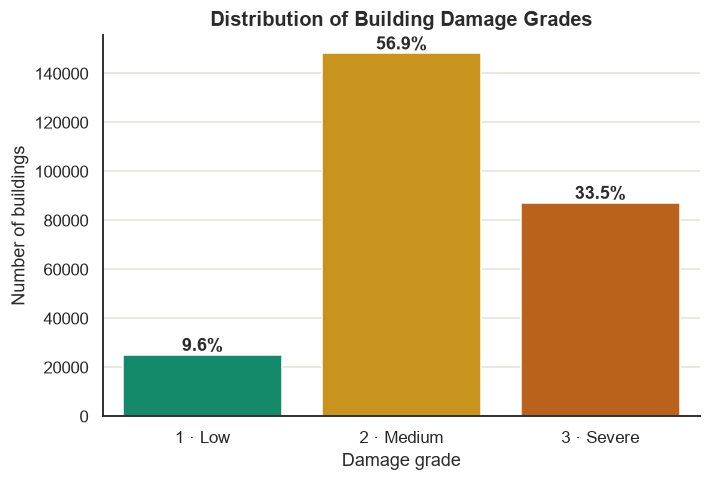

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(data=df, x=TARGET, order=[1, 2, 3], hue=TARGET, palette=DAMAGE_COLORS, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height() / len(df):.1%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontweight="bold")
ax.set_xticklabels([GRADE_NAMES[g] for g in (1, 2, 3)])
ax.set(title="Distribution of Building Damage Grades", xlabel="Damage grade", ylabel="Number of buildings")
plt.show()

## Q2.2 Do building size and age separate the damage grades?
**Why we ask:** if a feature's distribution is the same for all three grades, it carries little signal on its own.
**How to read:** one curve per damage grade, overlaid. Curves that sit apart mean the feature separates the grades. Curves that overlap mean it does not.
**What to look for:** **height** and **floors** (they set the building's mass and natural period) and **age** (unknown ages are left out of the plot).
**How the code works:** histograms with a smoothed curve (KDE), drawn as densities so the three grades are comparable even though their sizes differ. The second row of plots uses boxen plots, which show the spread of each feature per grade, including the tails.

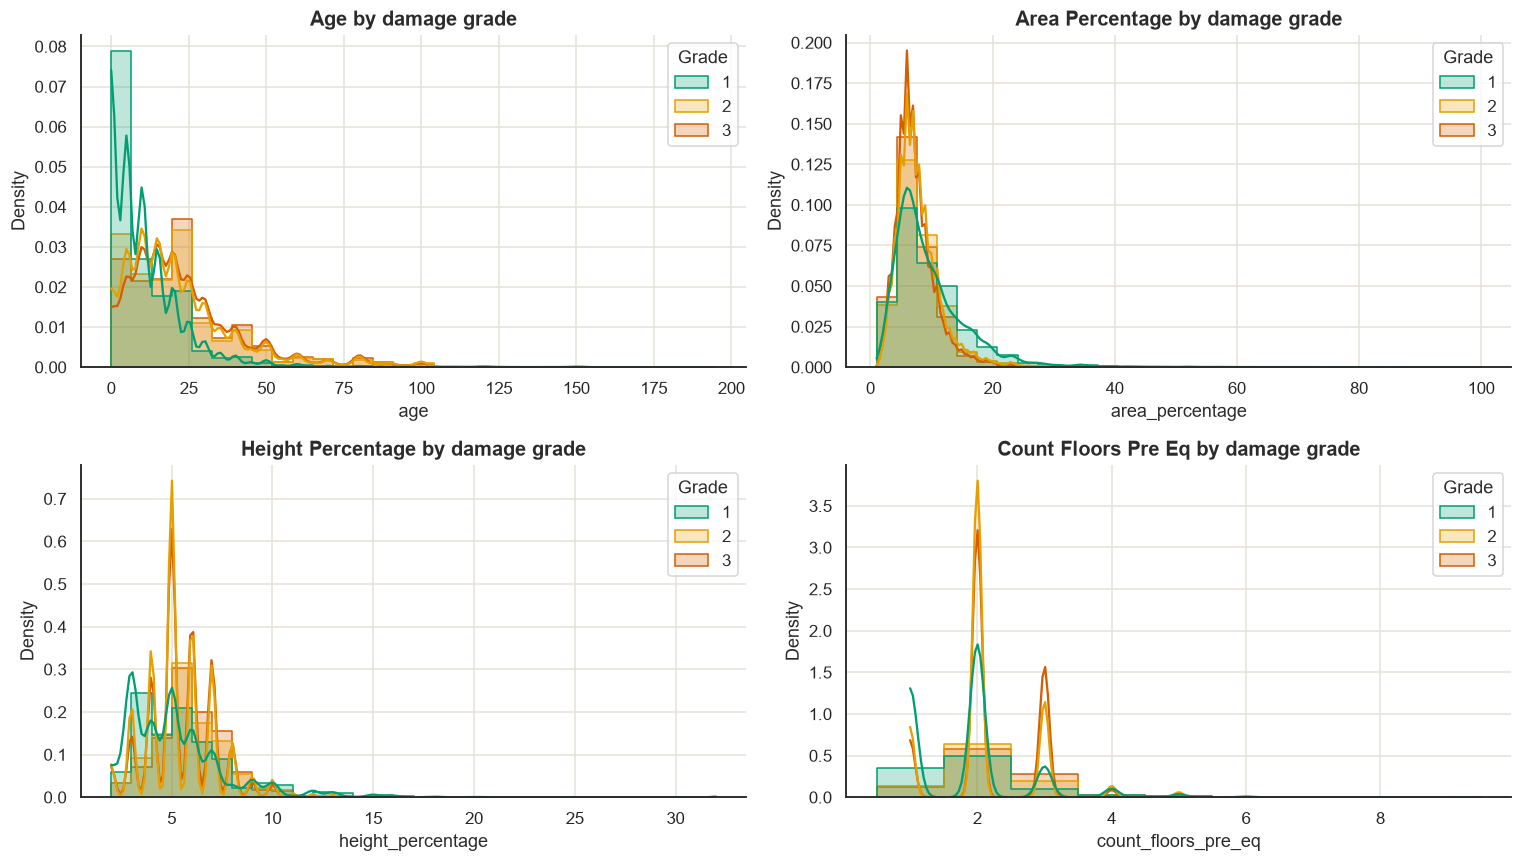

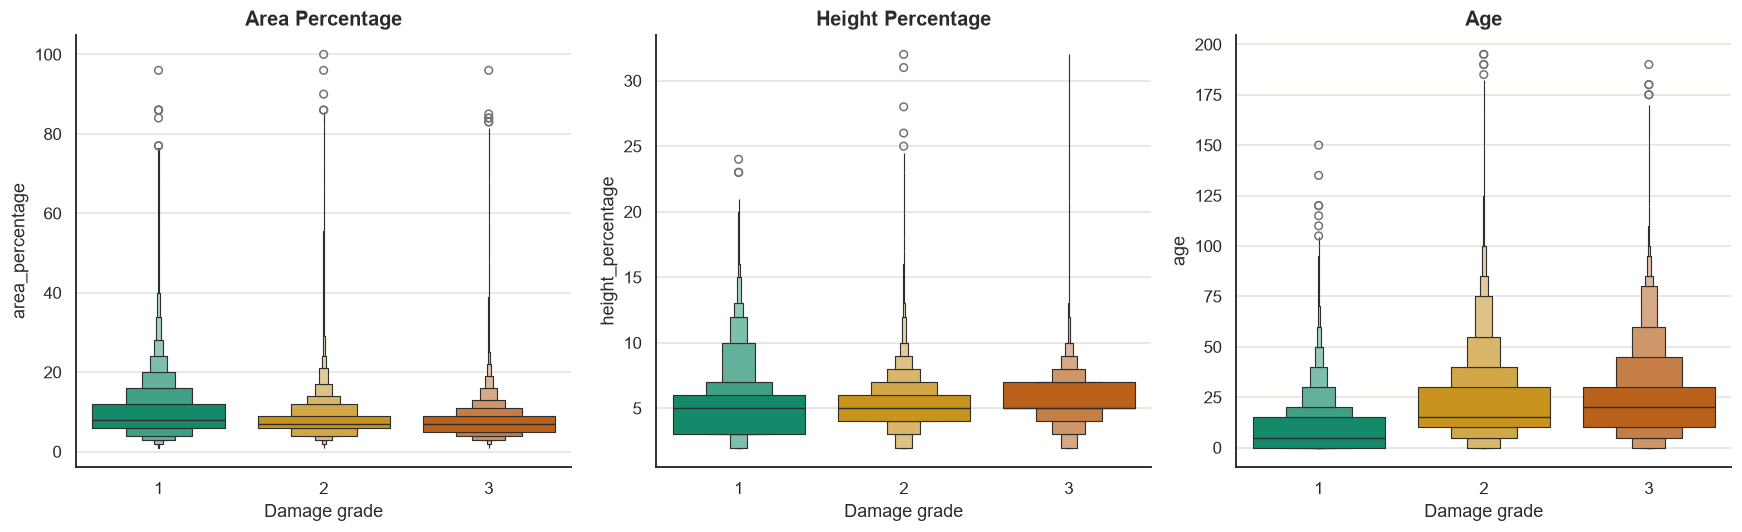

In [10]:
num_plot = ["age", "area_percentage", "height_percentage", "count_floors_pre_eq"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), num_plot):
    kw = dict(discrete=True) if col == "count_floors_pre_eq" else dict(bins=30)
    sns.histplot(data=df, x=col, hue=TARGET, palette=DAMAGE_COLORS, kde=True, element="step",
                 stat="density", common_norm=False, ax=ax, **kw)
    ax.set_title(col.replace("_", " ").title() + " by damage grade")
    if ax.get_legend(): ax.get_legend().set_title("Grade")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["area_percentage", "height_percentage", "age"]):
    sns.boxenplot(data=df, x=TARGET, y=col, hue=TARGET, palette=DAMAGE_COLORS, legend=False, ax=ax)
    ax.set_title(col.replace("_", " ").title()); ax.set_xlabel("Damage grade")
plt.tight_layout(); plt.show()

## Q2.3 Which construction choices separate survivors from collapses?
**Why we ask:** construction type is the main engineering lever. Weak foundations, mud ground floors and heavy roofs on weak walls should show worse outcomes.
**How to read:** each bar is 100% of the buildings with that characteristic, split by damage grade. The more **vermilion**, the more severe the damage.
**What to look for:** foundation, ground floor and roof types where vermilion dominates, and buildings attached on several sides or with irregular plans.
**How the code works:** for each categorical feature, `pd.crosstab(..., normalize="index")` converts counts to row percentages, and the result is drawn as a stacked bar. The last panel holds the legend.

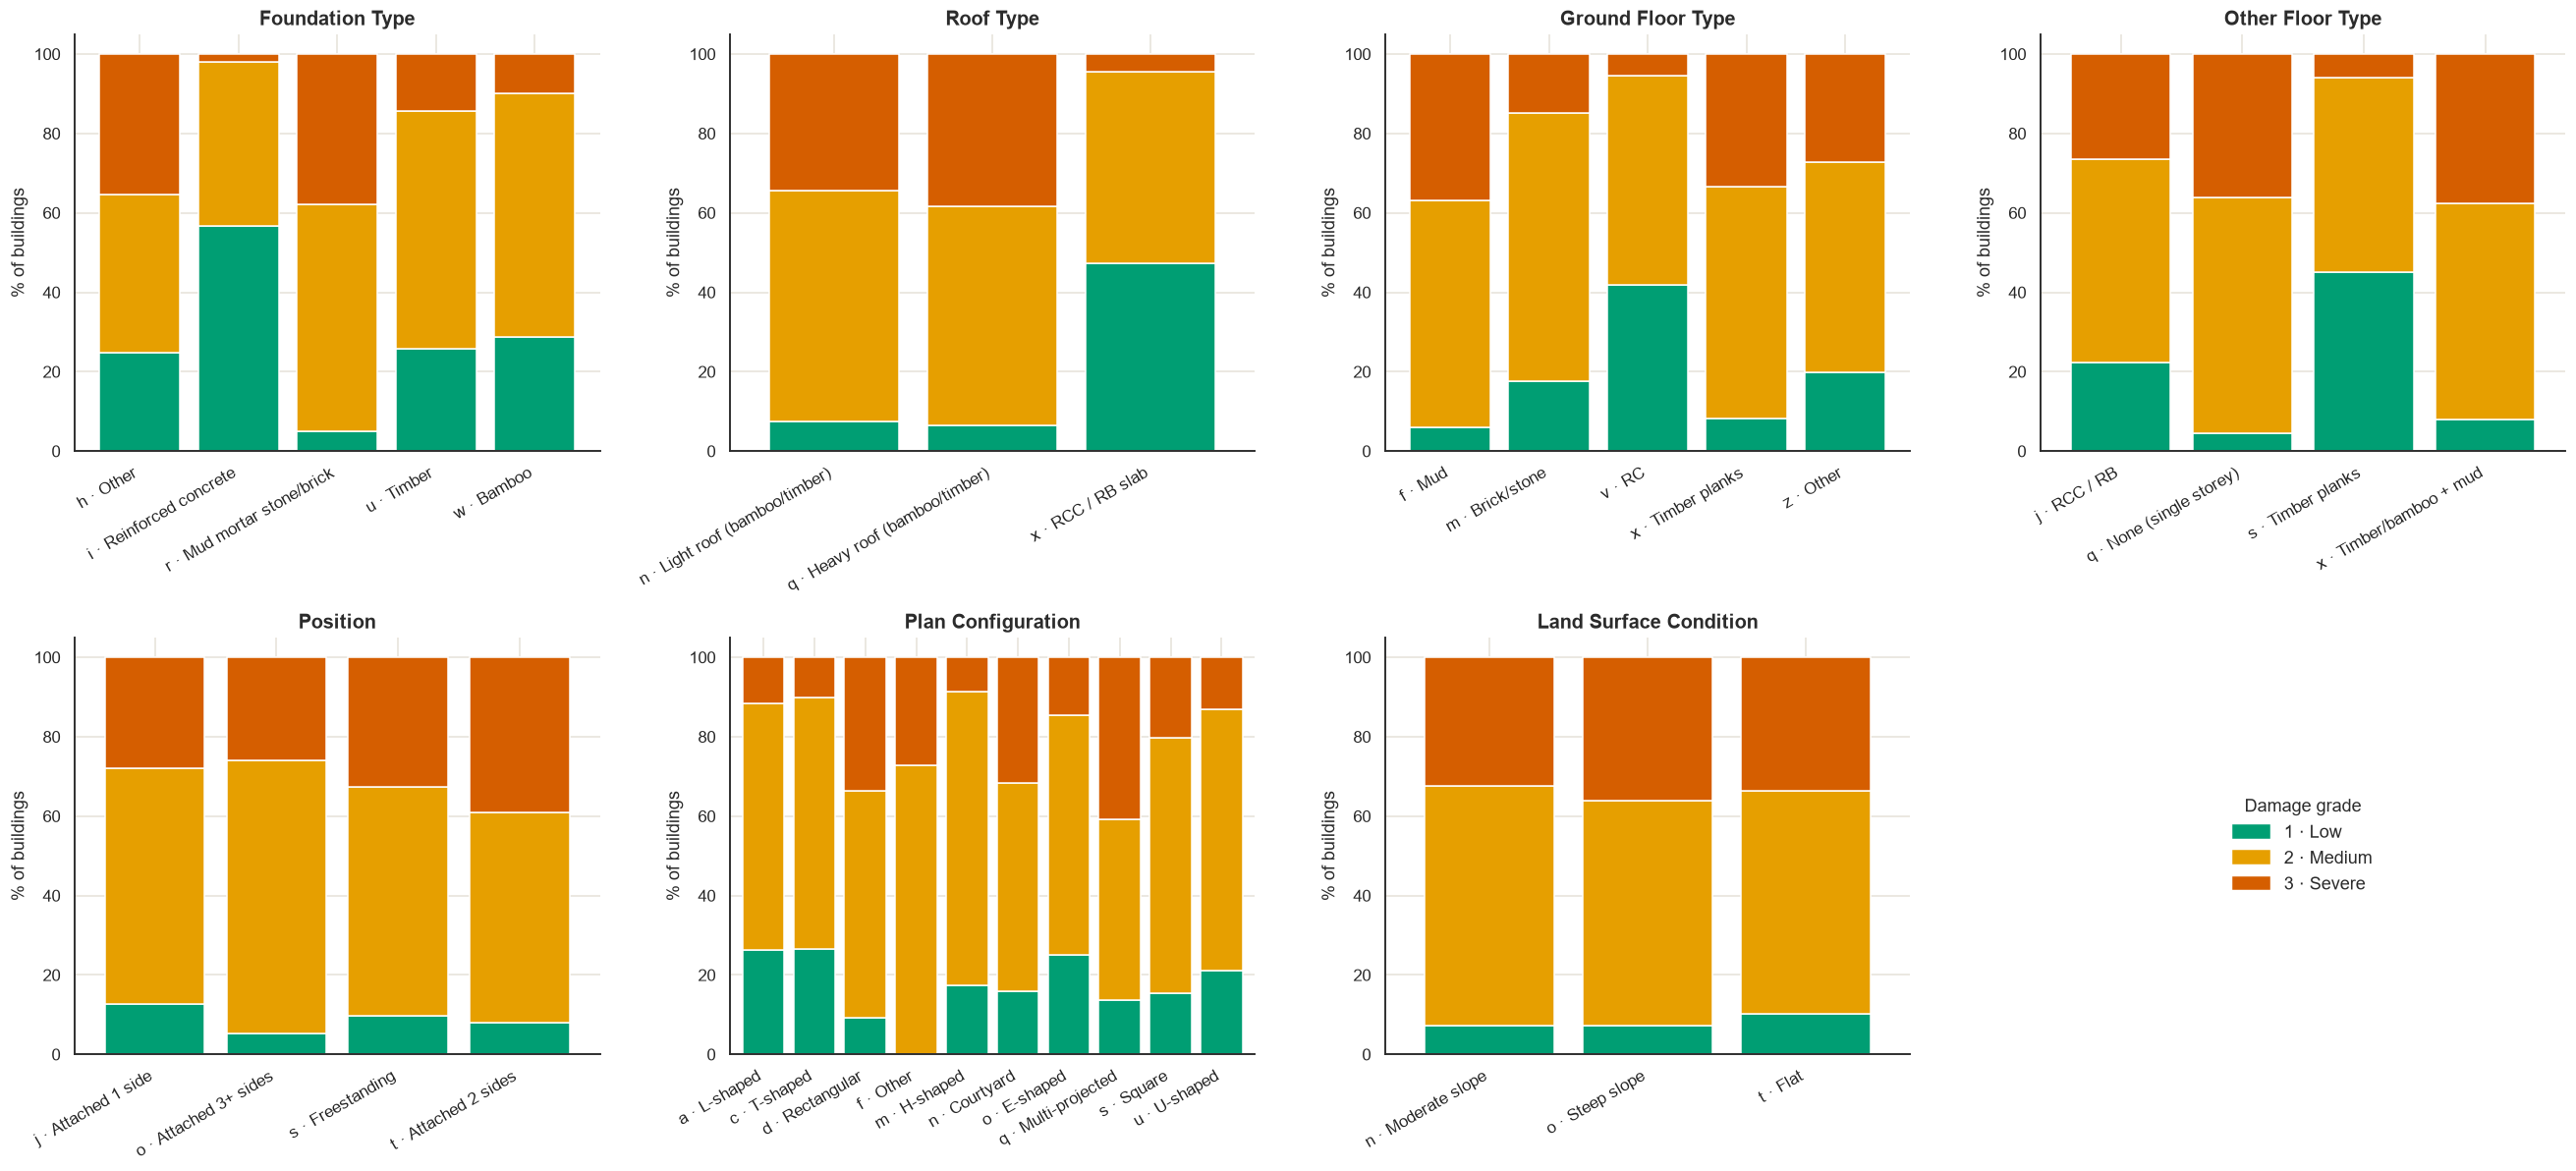

In [11]:
cat_plot = ["foundation_type", "roof_type", "ground_floor_type", "other_floor_type",
            "position", "plan_configuration", "land_surface_condition"]
fig, axes = plt.subplots(2, 4, figsize=(24, 11)); axes = axes.ravel()
for ax, col in zip(axes, cat_plot):
    ct = pd.crosstab(eda[col], eda[TARGET], normalize="index") * 100
    ct.plot(kind="bar", stacked=True, color=PALETTE, ax=ax, width=0.82, legend=False)
    ax.set_title(col.replace("_", " ").title()); ax.set_xlabel(""); ax.set_ylabel("% of buildings")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
axes[-1].axis("off"); axes[-1].legend(handles=GRADE_LEGEND, loc="center", title="Damage grade", frameon=False, fontsize=12)
plt.tight_layout(); plt.show()

## Q2.4 Which structural materials are most fragile?
**Why we ask:** materials are the strongest physical explanation for damage, so we quantify it.
**How to read:** the left chart shows how common each material is. The right chart shows the **% of buildings with that material that reached grade 3**, against the overall rate (dashed line). Bars past the dashed line are worse than average.
**Engineering context:** mud-mortar and adobe walls are heavy and brittle and cannot dissipate energy, while engineered reinforced concrete is designed to deform without collapsing.
**How the code works:** for every `has_superstructure_*` column we count the buildings that have it and compute the share of those that are grade 3.

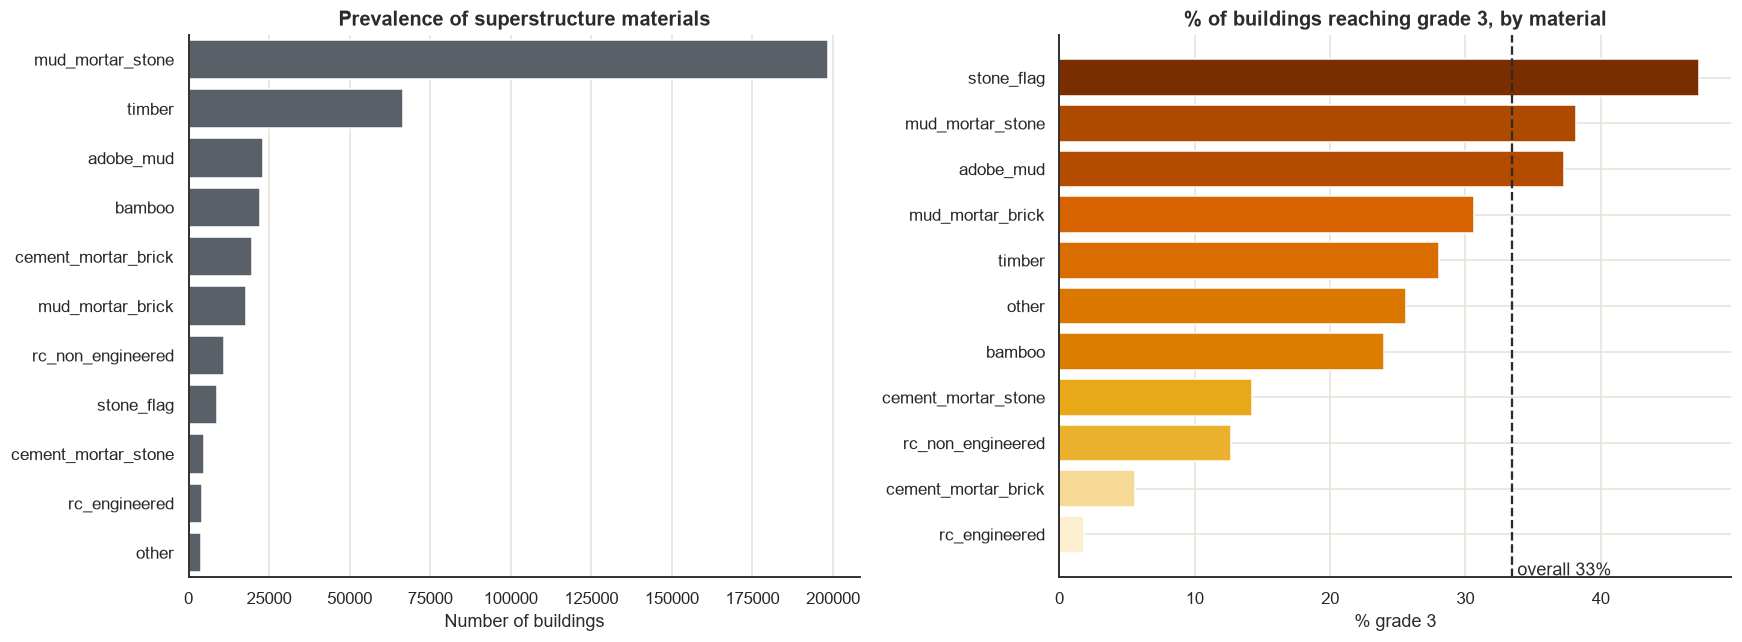

In [12]:
sup_stats = pd.DataFrame({"material": [c.replace("has_superstructure_", "") for c in SUP],
                          "buildings": [int(df[c].sum()) for c in SUP],
                          "severe_pct": [(df.loc[df[c] == 1, TARGET] == 3).mean() * 100 for c in SUP]})
overall_sev = (df[TARGET] == 3).mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
s1 = sup_stats.sort_values("buildings", ascending=False)
sns.barplot(data=s1, y="material", x="buildings", color=ACCENT, ax=axes[0])
axes[0].set(title="Prevalence of superstructure materials", xlabel="Number of buildings", ylabel="")
s2 = sup_stats.sort_values("severe_pct")
axes[1].barh(s2["material"], s2["severe_pct"], color=RISK_CMAP(s2["severe_pct"] / s2["severe_pct"].max()))
axes[1].axvline(overall_sev, ls="--", color=INK); axes[1].text(overall_sev, -0.9, f" overall {overall_sev:.0f}%", color=INK)
axes[1].set(title="% of buildings reaching grade 3, by material", xlabel="% grade 3")
plt.tight_layout(); plt.show()

## Q2.5 What happens when materials are combined?
**Why we ask:** a real building often mixes materials, and the combination matters more than any single material.
**How to read:** each row is one of the 12 most common material combinations, and each cell is the share of that combination in a damage grade. Rows are sorted from least to most severe.
**How the code works:** it builds a label like `mud_mortar_stone + timber` for every building, keeps the 12 most frequent labels, and cross-tabulates them with damage grade. The label includes the number of buildings so you can judge how reliable each row is.

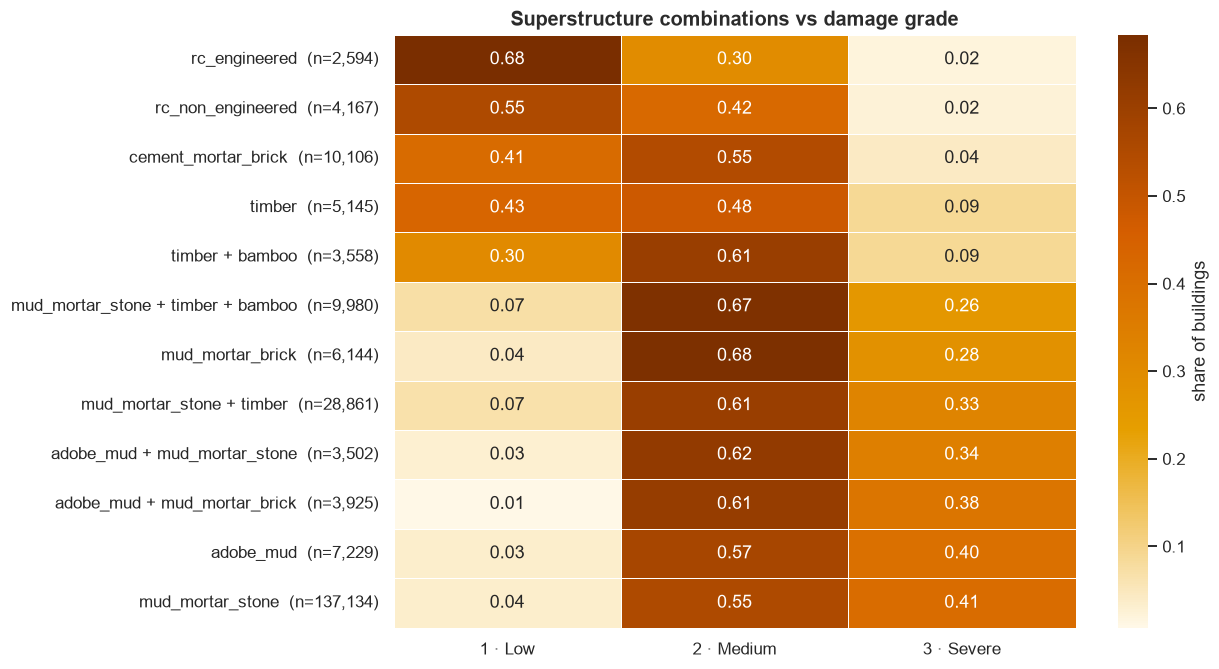

In [13]:
SHORT = {c: c.replace("has_superstructure_", "").replace("_flag", "") for c in SUP}
combo = pd.Series("", index=df.index)
for c in SUP:
    combo = combo + np.where(df[c] == 1, SHORT[c] + " + ", "")
combo = combo.str.rstrip(" +").replace("", "none")
top = combo.value_counts().head(12)
sub = df.loc[combo.isin(top.index)]
heat = pd.crosstab(combo[sub.index], sub[TARGET], normalize="index")
heat.index = [f"{i}  (n={top[i]:,})" for i in heat.index]
heat.columns = [GRADE_NAMES[g] for g in heat.columns]
heat = heat.sort_values(GRADE_NAMES[3])
plt.figure(figsize=(10, 7))
sns.heatmap(heat, annot=True, fmt=".2f", cmap=RISK_CMAP, linewidths=0.6, cbar_kws={"label": "share of buildings"})
plt.title("Superstructure combinations vs damage grade"); plt.ylabel(""); plt.show()

## Q2.6 How are the numeric features related?
**Why we ask:** to spot features that move together (redundant) or that relate strongly to damage.
**How to read:** teal means a negative relationship, vermilion a positive one, and the number is the strength (-1 to +1). We use **Spearman** correlation because it only needs a consistent ordering, which suits an ordinal target.
**Limit:** correlation only sees one-directional patterns. Interactions, such as a heavy roof on weak walls, will not show here, but the model can learn them.

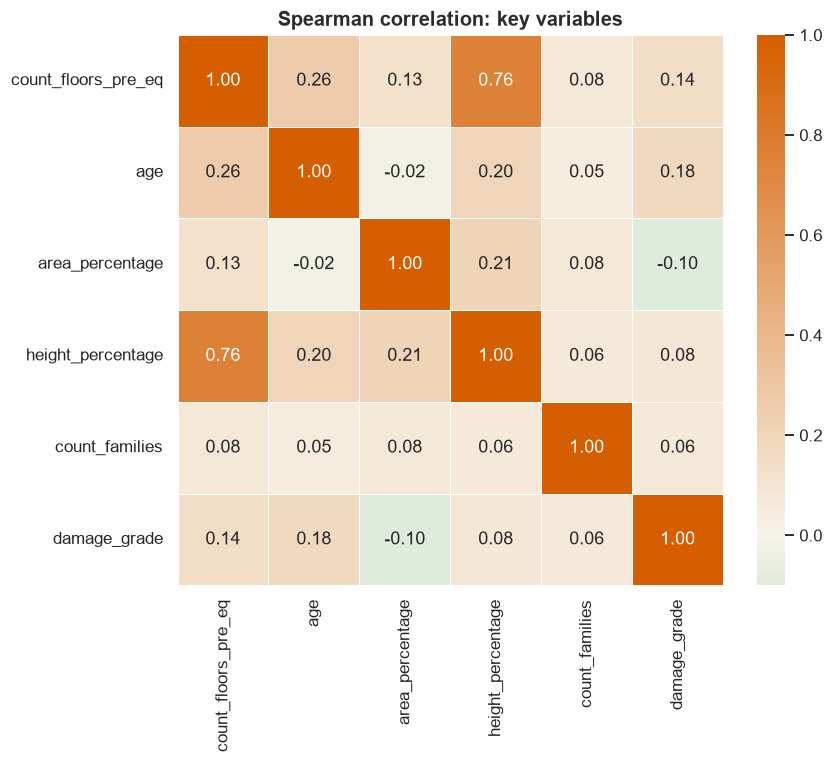

In [14]:
corr_cols = ["count_floors_pre_eq", "age", "area_percentage", "height_percentage", "count_families", TARGET]
plt.figure(figsize=(8, 6.5))
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap=DIVERGING, center=0, linewidths=0.5)
plt.title("Spearman correlation: key variables"); plt.show()

## Q2.7 Does *where* a building stands matter?
**Why we ask:** the dataset has no shaking measurements, so location is our only stand-in for how hard the ground shook and how soft the soil was.
**How to read:** each row is one of the 31 regions (`geo_level_1_id`), sorted from least to most severe, and each cell is the share of that region in a damage grade.
**Why this matters for the model:** if regions differ sharply, location must be handled with care. That is why Chapter 5 gives geography its own encoder instead of treating the IDs as ordinary numbers.

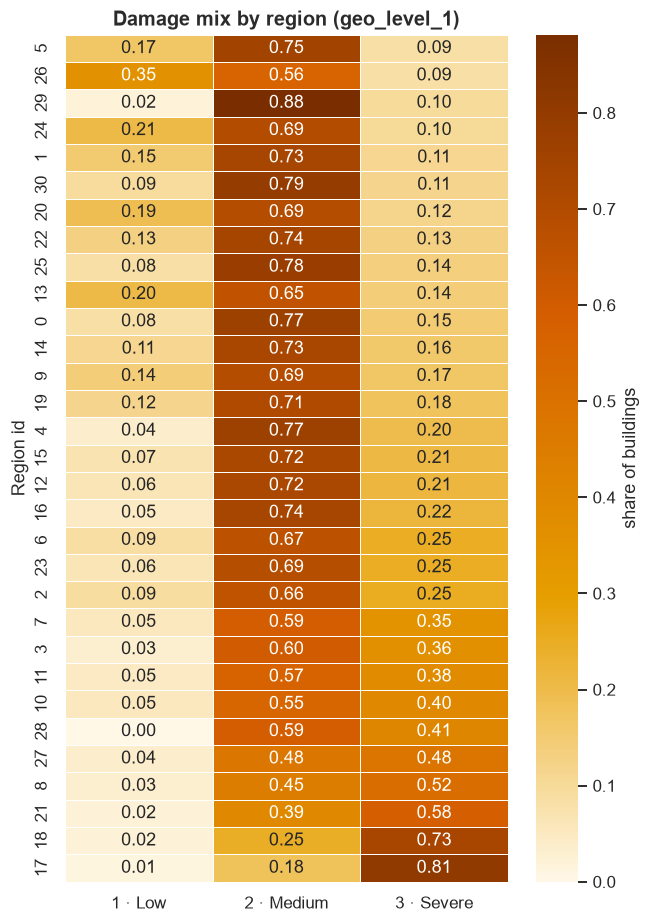

In [15]:
geo_mix = pd.crosstab(df["geo_level_1_id"], df[TARGET], normalize="index").sort_values(3)
geo_mix.columns = [GRADE_NAMES[g] for g in geo_mix.columns]
plt.figure(figsize=(6.5, 10))
sns.heatmap(geo_mix, annot=True, fmt=".2f", cmap=RISK_CMAP, linewidths=0.4, cbar_kws={"label": "share of buildings"})
plt.title("Damage mix by region (geo_level_1)"); plt.ylabel("Region id"); plt.show()

## Q2.8 Interactive views
**Why we add these:** static charts hide detail, and these let you hover and zoom.
- **Scatter:** footprint vs height, split by foundation and shaped by roof type. Look for tall, narrow buildings on weak foundations.
- **Sunburst:** regions → districts, sized by building count and coloured by average damage. Click a region to zoom in.
- **Parallel categories:** follow a path of foundation → roof → ground floor to see which combinations end in grade 3.

**How the code works:** plotly draws all three. We sample 15,000–20,000 buildings for the scatter and parallel plots so they stay fast, and the sunburst shows only the six largest regions and their six largest districts.

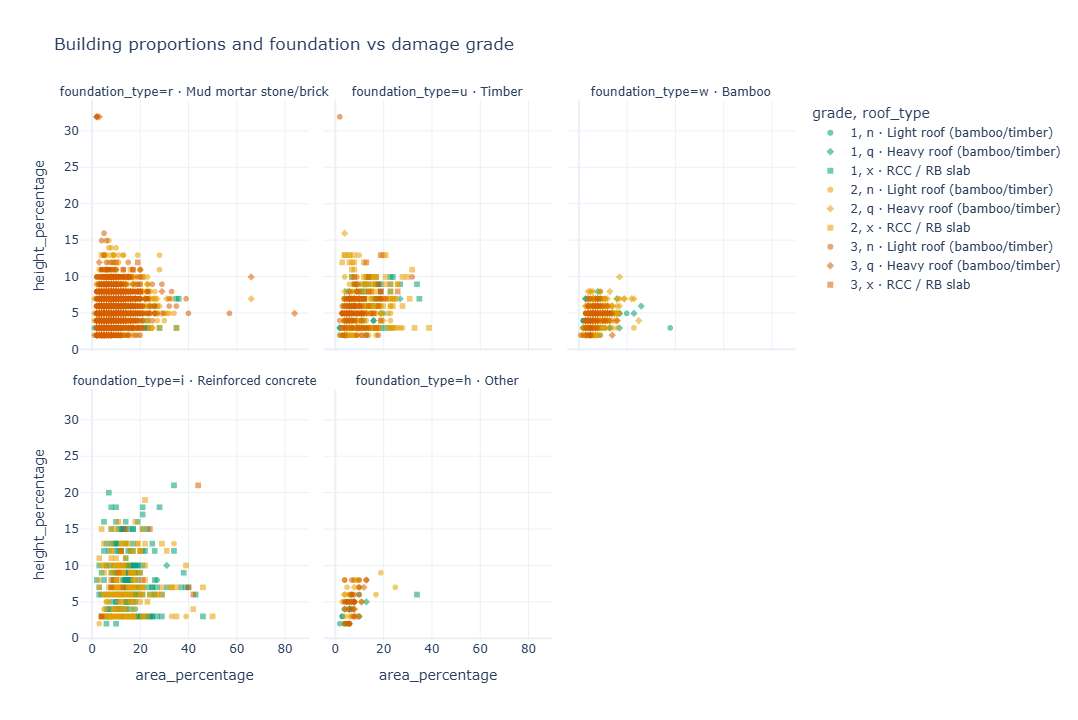

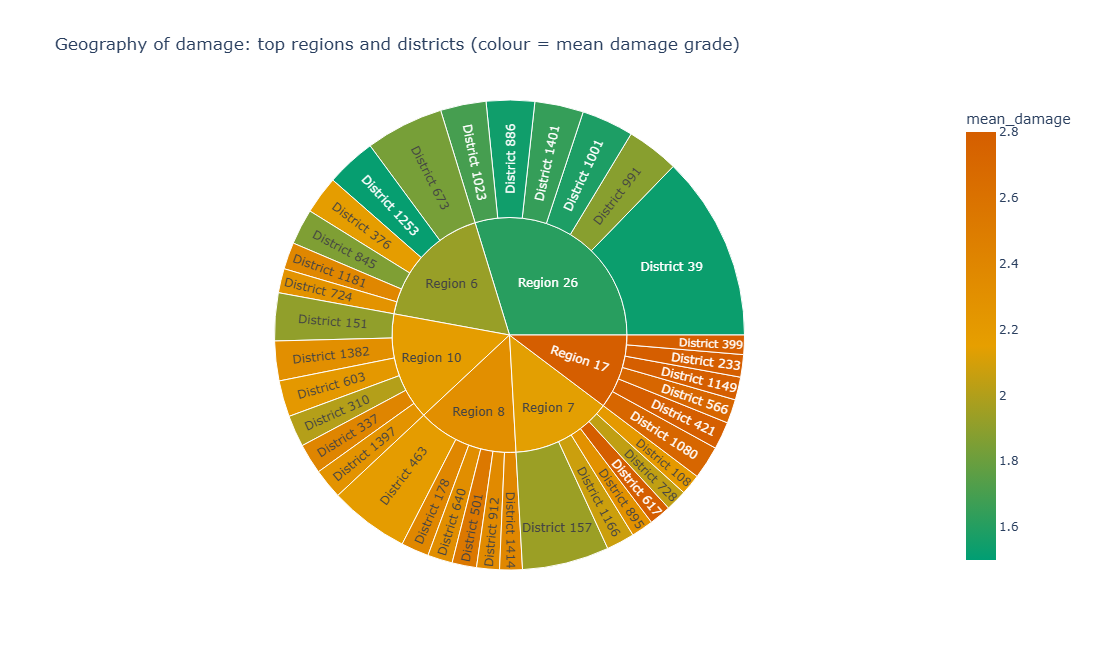

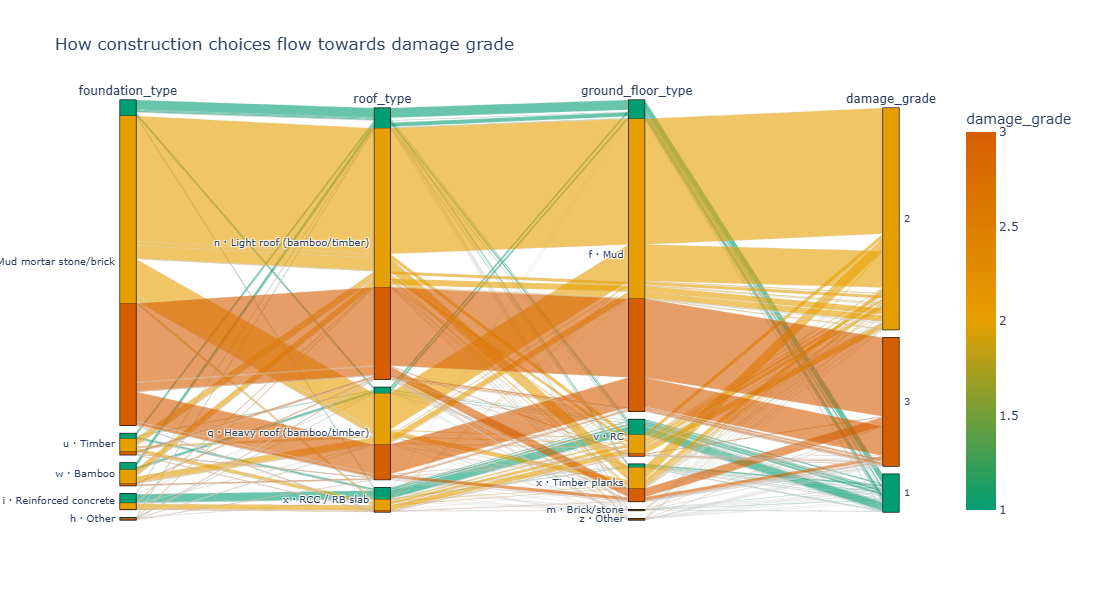

In [16]:
GRADE_MAP = {"1": DAMAGE_COLORS[1], "2": DAMAGE_COLORS[2], "3": DAMAGE_COLORS[3]}

# 1) Scatter: proportions by foundation, symbol = roof
samp = eda.sample(min(15000, len(eda)), random_state=SEED).assign(grade=lambda d: d[TARGET].astype(str))
fig = px.scatter(samp, x="area_percentage", y="height_percentage", color="grade", symbol="roof_type",
                 facet_col="foundation_type", facet_col_wrap=3, opacity=0.55,
                 color_discrete_map=GRADE_MAP, category_orders={"grade": ["1", "2", "3"]},
                 hover_data=["age", "count_floors_pre_eq"],
                 title="Building proportions and foundation vs damage grade")
fig.update_layout(height=720); fig.show()

# 2) Sunburst: region → district, coloured by average damage grade
agg = (df.groupby(["geo_level_1_id", "geo_level_2_id"])
         .agg(n=(TARGET, "size"), mean_damage=(TARGET, "mean")).reset_index())
top_regions = df["geo_level_1_id"].value_counts().head(6).index
agg = (agg[agg["geo_level_1_id"].isin(top_regions)].sort_values("n")
          .groupby("geo_level_1_id").tail(6))
agg["region"]   = "Region " + agg["geo_level_1_id"].astype(str)
agg["district"] = "District " + agg["geo_level_2_id"].astype(str)
fig = px.sunburst(agg, path=["region", "district"], values="n", color="mean_damage",
                  color_continuous_scale=RISK_SCALE, range_color=[1.5, 2.8],
                  title="Geography of damage: top regions and districts (colour = mean damage grade)")
fig.update_layout(height=650); fig.show()

# 3) Parallel categories
pc = eda.sample(min(20000, len(eda)), random_state=SEED)
fig = px.parallel_categories(pc, dimensions=["foundation_type", "roof_type", "ground_floor_type", TARGET],
                             color=TARGET, color_continuous_scale=RISK_SCALE,
                             title="How construction choices flow towards damage grade")
fig.update_layout(height=600); fig.show()

## What the exploration tells us
- **Location and material dominate.** Damage varies sharply between regions, and weak masonry is far more fragile than engineered concrete. Our engineered features and our location handling should therefore be our biggest levers.
- **Interactions matter.** A heavy roof is far worse on mud-mortar walls than on a reinforced frame. Single-feature charts cannot show this, but boosted trees can learn it, and we will give them explicit hints.
- **Grade 2 is the "hard middle".** Most mistakes will be between *adjacent* grades, which is why we will track ordinal metrics as well as accuracy.

# Chapters 3 & 4 · Features, then the split
The next cell builds the engineered features, and the one after it splits the data. This order is safe because these features use **no damage labels**, so nothing leaks.

**The split rule:** 20% of buildings are locked away as a hold-out and are only used for the final score. All tuning and model selection use cross-validation on the other 80%. The split is *stratified*, so the grade mix (9.6 / 56.9 / 33.5%) is the same in both parts.

# Chapter 4 · Feature engineering through a seismologist's eyes
**What:** add new columns that express engineering physics, not just statistics.
**Why:** a model can only use what we give it. Raw measurements do not tell it that tall narrow buildings sway more or that a heavy roof is worse on weak walls. We state those ideas explicitly.

| Feature | Physical idea |
|---|---|
| `storey_height` | Tall storeys are more flexible and prone to soft-storey failure |
| `slenderness` (height ÷ footprint) | Tall, narrow buildings sway and overturn more easily |
| `floor_area_total` | A proxy for mass, and so for inertial force |
| `weak_masonry`, `has_rc`, `n_materials` | A material vulnerability class |
| `roof_heavy`, `heavy_roof_weak` | A heavy roof raises the force at the top, and is worst on weak walls |
| `irregular_plan`, `attached` | Torsion in non-rectangular plans, and pounding between neighbours |
| `steep_site` | Topographic amplification of shaking |
| `age_x_weak` | Ageing masonry weakened by decades of weathering |
| `g2_*`, `g3_*` (neighbourhood context) | The local building stock in each district and village: how many buildings, how tall, how old, how much weak masonry |

**How the code works:** `basic_features()` creates the per-building features. `build_context()` computes the neighbourhood averages from the building features only, so no labels are used. `make_features()` combines them, adds two "this building vs its district" comparisons, and the bar chart afterwards checks which new features relate to damage.

Feature count: 67 | rows: 260601


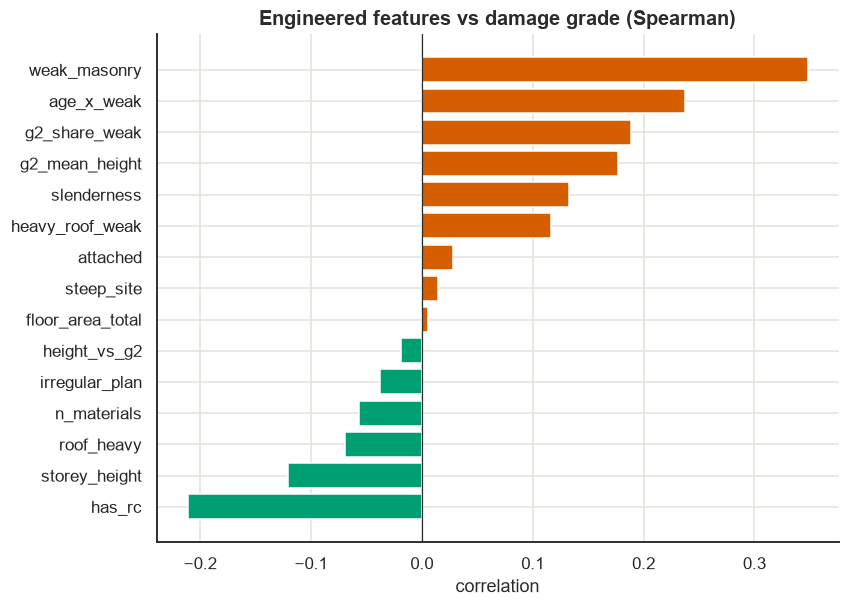

In [17]:
WEAK = ["has_superstructure_adobe_mud", "has_superstructure_mud_mortar_stone", "has_superstructure_mud_mortar_brick"]
RC   = ["has_superstructure_rc_non_engineered", "has_superstructure_rc_engineered"]

def basic_features(d):
    d = d.copy()
    d["storey_height"]     = d["height_percentage"] / d["count_floors_pre_eq"]
    d["slenderness"]       = d["height_percentage"] / d["area_percentage"]
    d["floor_area_total"]  = d["area_percentage"] * d["count_floors_pre_eq"]
    d["n_materials"]       = d[SUP].sum(axis=1)
    d["weak_masonry"]      = d[WEAK].max(axis=1)
    d["has_rc"]            = d[RC].max(axis=1)
    d["roof_heavy"]        = (d["roof_type"] != "n").astype("int8")
    d["heavy_roof_weak"]   = d["roof_heavy"] * d["weak_masonry"]
    d["irregular_plan"]    = (~d["plan_configuration"].isin(["d", "s"])).astype("int8")
    d["attached"]          = (d["position"] != "s").astype("int8")
    d["steep_site"]        = (d["land_surface_condition"] == "o").astype("int8")
    d["n_secondary_use"]   = d[SEC].sum(axis=1)
    d["age_x_weak"]        = d["age"] * d["weak_masonry"]
    return d

# Label-free neighbourhood statistics (built from train + test features; no damage labels involved)
def build_context(frames):
    allx = basic_features(pd.concat(frames, ignore_index=True))
    tables = {}
    for g, tag in (("geo_level_2_id", "g2"), ("geo_level_3_id", "g3")):
        tables[g] = (allx.groupby(g).agg(**{f"{tag}_n_buildings": (ID, "size"),
                                            f"{tag}_mean_height": ("height_percentage", "mean"),
                                            f"{tag}_mean_floors": ("count_floors_pre_eq", "mean"),
                                            f"{tag}_mean_age": ("age", "mean"),
                                            f"{tag}_share_weak": ("weak_masonry", "mean"),
                                            f"{tag}_share_rc": ("has_rc", "mean")}).reset_index())
    return tables

CTX = build_context([df.drop(columns=TARGET)] + ([test_clean] if test_clean is not None else []))

def make_features(frame):
    d = basic_features(frame)
    for g, tbl in CTX.items():
        d = d.merge(tbl, on=g, how="left")
    d["height_vs_g2"] = d["height_percentage"] - d["g2_mean_height"]
    d["weak_vs_g2"]   = d["weak_masonry"] - d["g2_share_weak"]
    return d

X_full = make_features(df.drop(columns=TARGET))
y_full = df[TARGET].values - 1                     # 0,1,2 = grades 1,2,3 (keeps the order)
FEATURES = [c for c in X_full.columns if c != ID]
print("Feature count:", len(FEATURES), "| rows:", len(X_full))

# Do the new physics features relate to damage?
new_feats = ["storey_height", "slenderness", "floor_area_total", "n_materials", "weak_masonry", "has_rc",
             "roof_heavy", "heavy_roof_weak", "irregular_plan", "attached", "steep_site", "age_x_weak",
             "g2_share_weak", "g2_mean_height", "height_vs_g2"]
sp = X_full[new_feats].corrwith(pd.Series(y_full, index=X_full.index), method="spearman").sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(sp.index, sp.values, color=[PALETTE[2] if v > 0 else PALETTE[0] for v in sp.values])
ax.axvline(0, color=INK, lw=0.8); ax.set(title="Engineered features vs damage grade (Spearman)", xlabel="correlation")
plt.show()

## The split · locking away the hold-out
We keep 20% of buildings unseen until the end, so the final score is honest. The cross-validation object `cv` (5 folds) is created here and reused for every model, so all models are compared on identical data. **Check:** both parts show the same grade mix, with 208,480 buildings in development and 52,121 in the hold-out.

In [18]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X_dev, X_hold, y_dev, y_hold = train_test_split(X_full, y_full, test_size=0.20, stratify=y_full, random_state=SEED)
if QUICK_MODE:                                       # dry run on a subsample
    keep = np.random.RandomState(SEED).choice(len(X_dev), 30000, replace=False)
    X_dev, y_dev = X_dev.iloc[keep], y_dev[keep]
X_dev, X_hold = X_dev.reset_index(drop=True), X_hold.reset_index(drop=True)

cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
print(f"Development set: {len(X_dev):,}   |   Locked hold-out: {len(X_hold):,}")
print("Grade mix dev  :", np.round(np.bincount(y_dev) / len(y_dev), 3))
print("Grade mix hold :", np.round(np.bincount(y_hold) / len(y_hold), 3))

Development set: 208,480   |   Locked hold-out: 52,121
Grade mix dev  : [0.096 0.569 0.335]
Grade mix hold : [0.096 0.569 0.335]


## The split · locking away the hold-out
**What:** divide the buildings into a **development set** (80%) and a **hold-out set** (20%).
**Why:** the hold-out plays the role of "buildings the model has never seen". If we peeked at it during tuning, our final score would be optimistic. Keeping it locked until Chapter 9 makes the final accuracy honest.
**How:** `train_test_split(..., stratify=y)` keeps the grade mix identical in both parts. The cross-validation object `cv` (5 folds) is created here and reused for every comparison, so all models are tested on exactly the same data.
**Check:** both parts show the same mix (9.6% / 56.9% / 33.5%), with 208,480 buildings in development and 52,121 in the hold-out.

# Chapter 5 · A leak-proof modelling pipeline
Anything that *learns from the target* must learn from training data only, otherwise the scores look better than reality. So it all lives inside one pipeline.

**The one custom step, `GeoTargetEncoder`.** There are 1,414 districts and 11,595 villages, far too many to one-hot encode, and their ID numbers have no real order. So each location is replaced by its **historic damage rate**. Two safeguards:
- **Out-of-fold:** while training, a building's value is computed from *other* folds, so it never sees its own label.
- **Smoothing:** a village with only a few buildings is pulled towards the overall average, so a tiny sample cannot mislead the model.

Other categories are passed as codes and read natively by the trees, and missing ages stay missing.

In [19]:
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

class GeoTargetEncoder(BaseEstimator, TransformerMixin):
    """Out-of-fold, smoothed target encoding of geography using two ordinal targets (grade>=2, grade==3)."""
    def __init__(self, cols=("geo_level_2_id", "geo_level_3_id"), smoothing=20.0, n_splits=5, seed=42):
        self.cols, self.smoothing, self.n_splits, self.seed = cols, smoothing, n_splits, seed

    @staticmethod
    def _targets(y):
        y = np.asarray(y); return np.column_stack([y >= 1, y >= 2]).astype(float)

    def _stats(self, X, T):
        return {c: pd.DataFrame({"k": np.asarray(X[c]), "d": T[:, 0], "s": T[:, 1]})
                      .groupby("k").agg(n=("d", "size"), d=("d", "sum"), s=("s", "sum")) for c in self.cols}

    def _encode(self, X, stats):
        out = {}
        for c in self.cols:
            g = stats[c].reindex(np.asarray(X[c])).fillna(0.0)
            n = g["n"].to_numpy()
            out[f"te_{c}_damaged"] = (g["d"].to_numpy() + self.smoothing * self.prior_[0]) / (n + self.smoothing)
            out[f"te_{c}_severe"]  = (g["s"].to_numpy() + self.smoothing * self.prior_[1]) / (n + self.smoothing)
        return pd.DataFrame(out, index=X.index)

    def fit(self, X, y):
        T = self._targets(y); self.prior_ = T.mean(axis=0); self.stats_ = self._stats(X, T); return self

    def fit_transform(self, X, y=None):
        self.fit(X, y); T = self._targets(y)
        oof = np.zeros((len(X), 2 * len(self.cols)))
        for tr, va in KFold(self.n_splits, shuffle=True, random_state=self.seed).split(X):
            enc = self._encode(X.iloc[va], self._stats(X.iloc[tr], T[tr]))
            oof[va] = enc.to_numpy(); names = list(enc.columns)
        return pd.concat([X, pd.DataFrame(oof, index=X.index, columns=names)], axis=1)

    def transform(self, X):
        return pd.concat([X, self._encode(X, self.stats_)], axis=1)

CAT_NATIVE = CAT_COLS + ["geo_level_1_id"]        # categorical, handled natively by the trees
N_CAT      = len(CAT_NATIVE)
TE_COLS    = [f"te_{c}_{t}" for c in ("geo_level_2_id", "geo_level_3_id") for t in ("damaged", "severe")]

def make_pre(linear=False):
    if not linear:   # trees: categorical codes first (so indices 0..N_CAT-1 are categorical), numerics pass through
        return ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), CAT_NATIVE)],
                                 remainder="passthrough")
    num = [c for c in FEATURES + TE_COLS if c not in CAT_NATIVE and c not in ("geo_level_2_id", "geo_level_3_id")]
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT_NATIVE),
                              ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num)])

def make_pipe(estimator, linear=False):
    return Pipeline([("geo", GeoTargetEncoder(n_splits=N_FOLDS, seed=SEED)), ("pre", make_pre(linear)), ("model", estimator)])
print("Pipeline blueprint ready · categorical columns:", N_CAT, "· target-encoded columns:", len(TE_COLS))

Pipeline blueprint ready · categorical columns: 9 · target-encoded columns: 4


# Chapter 6 · Validation metrics for a 3-class, *ordered* target
**Why many metrics:** accuracy alone would hide the problems that matter. A model could score well by always guessing the large middle class.

| Metric | Question it answers |
|---|---|
| **Micro-F1** (= accuracy) | What share of buildings did we grade correctly? |
| **Macro-F1** | Do we do well on *every* grade, including the small ones? |
| **Per-grade precision / recall** | Of the buildings we call severe, how many are? Of the severe ones, how many did we find? |
| **Quadratic weighted kappa (QWK)** | Agreement that punishes two-step errors far more than one-step errors, which suits ordered grades |
| **MAE (grade distance)** | On average, how many grades are we off by? |
| **Severe → Low rate** | How often do we call a collapsing building "low damage"? This is the most dangerous mistake. |
| **ROC-AUC and log-loss** | How good are the *probabilities*, not just the final labels? |

**How the code works:** `metrics_dict()` computes all of them for one set of predictions. `fold_stats()` repeats the score across the same cross-validation folds to give a mean and a spread (±), so we can tell a real difference from noise.

In [20]:
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
                             roc_auc_score, log_loss, classification_report, confusion_matrix, precision_recall_fscore_support)

def metrics_dict(y_true, y_pred, proba=None):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rec = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)[1]
    m = {"micro_f1": f1_score(y_true, y_pred, average="micro"),
         "macro_f1": f1_score(y_true, y_pred, average="macro"),
         "balanced_acc": balanced_accuracy_score(y_true, y_pred),
         "mcc": matthews_corrcoef(y_true, y_pred),
         "qwk": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
         "mae_grades": np.abs(y_true - y_pred).mean(),
         "recall_g1": rec[0], "recall_g2": rec[1], "recall_g3": rec[2],
         "severe_as_low": ((y_true == 2) & (y_pred == 0)).sum() / max((y_true == 2).sum(), 1)}
    if proba is not None:
        m["roc_auc_ovr"] = roc_auc_score(y_true, proba, multi_class="ovr", average="macro")
        m["log_loss"]    = log_loss(y_true, proba, labels=[0, 1, 2])
    return m

def fold_stats(y_true, y_pred):
    """Mean ± std of micro-F1 and QWK across the same CV folds."""
    f, k = [], []
    for _, va in cv.split(np.zeros(len(y_true)), y_true):
        f.append(f1_score(y_true[va], y_pred[va], average="micro")); k.append(cohen_kappa_score(y_true[va], y_pred[va], weights="quadratic"))
    return np.mean(f), np.std(f), np.mean(k), np.std(k)
print("Metric helpers ready.")

Metric helpers ready.


# Chapter 7 · Which family of model suits an *ordered* target?
**What:** compare six models on identical data, using identical folds and the identical pipeline.
**Why:** a fair comparison needs the same conditions. The simple models are our reference, so we can tell whether a complex model is actually worth it.

| Model | Idea | Ordinal-aware? |
|---|---|---|
| Majority class | Always predict grade 2 | n/a: the floor to beat |
| Logistic regression | Linear benchmark | No |
| Decision tree | Simple, interpretable benchmark | No |
| **A · Multiclass gradient boosting** | One model, three classes | No |
| **B · Cumulative (Frank & Hall)** | Two yes/no models: "is it at least medium?" and "is it severe?", combined into three probabilities | **Yes** |
| **C · Regression + cut-points** | Predict a damage *score*, then learn the two thresholds that split it into grades | **Yes** |

**How the comparison works:** `cross_val_predict` gives every building a prediction from a model that never saw it (an **out-of-fold** prediction), and all metrics are computed on those honest predictions.

✓ Majority class               micro-F1 0.5689   (7s)
✓ Logistic regression          micro-F1 0.7377   (82s)
✓ Decision tree                micro-F1 0.7255   (33s)
✓ A · Multiclass GBM           micro-F1 0.7485   (227s)
✓ B · Cumulative GBM           micro-F1 0.7479   (175s)
✓ C · Regression + cutpoints   micro-F1 0.7475   (76s)


,micro_F1,± sd,QWK,macro_F1,MAE_grades,recall_G1,recall_G3,severe→low,seconds
model,,,,,,,,,
A · Multiclass GBM,0.749,0.001,0.623,0.701,0.255,0.556,0.643,0.007,226.888
B · Cumulative GBM,0.748,0.001,0.622,0.701,0.256,0.555,0.644,0.007,174.939
C · Regression + cutpoints,0.748,0.001,0.628,0.701,0.255,0.551,0.650,0.004,76.098
Logistic regression,0.738,0.001,0.602,0.681,0.266,0.498,0.631,0.006,82.376
Decision tree,0.726,0.002,0.580,0.667,0.279,0.494,0.611,0.008,33.088
Majority class,0.569,0.000,0.000,0.242,0.431,0.000,0.000,0.000,7.336


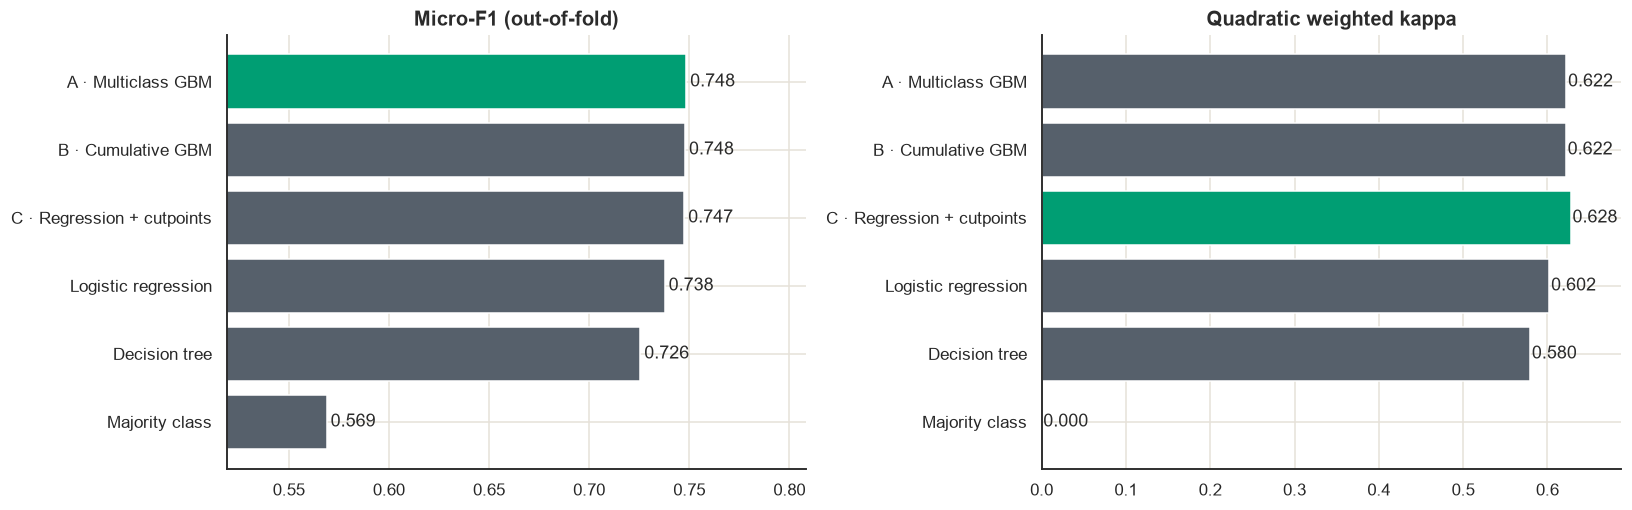

In [21]:
from sklearn.model_selection import cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor

def hgb(cls=HistGradientBoostingClassifier, **over):
    p = dict(max_iter=MAX_ITER, learning_rate=0.08, max_leaf_nodes=63, min_samples_leaf=40, l2_regularization=1.0,
             early_stopping=True, n_iter_no_change=25, validation_fraction=0.1, random_state=SEED,
             categorical_features=list(range(N_CAT)))
    p.update(over); return cls(**p)

class CumulativeOrdinalClassifier(ClassifierMixin, BaseEstimator):
    """Frank & Hall: one binary model per threshold (y>0, y>1), recombined into P(grade 1/2/3)."""
    def __init__(self, base=None):
        self.base = base
    def fit(self, X, y):
        y = np.asarray(y); self.classes_ = np.array([0, 1, 2])
        self.models_ = [clone(self.base).fit(X, (y > k).astype(int)) for k in (0, 1)]
        return self
    def predict_proba(self, X):
        p_gt1 = self.models_[0].predict_proba(X)[:, 1]
        p_gt2 = np.minimum(self.models_[1].predict_proba(X)[:, 1], p_gt1)     # keep probabilities consistent
        return np.column_stack([1 - p_gt1, p_gt1 - p_gt2, p_gt2])
    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

def best_thresholds(score, y, grid=np.linspace(0.3, 1.7, 57)):
    best = (-1, 0.5, 1.5)
    for t1 in grid:
        for t2 in grid[grid > t1]:
            acc = (np.digitize(score, [t1, t2]) == y).mean()
            if acc > best[0]: best = (acc, t1, t2)
    return best[1], best[2]

Xd = X_dev[FEATURES]
candidates = {
    "Majority class":            (make_pipe(DummyClassifier(strategy="prior")), "proba"),
    "Logistic regression":       (make_pipe(LogisticRegression(max_iter=300), linear=True), "proba"),
    "Decision tree":             (make_pipe(DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, random_state=SEED)), "proba"),
    "A · Multiclass GBM":        (make_pipe(hgb()), "proba"),
    "B · Cumulative GBM":        (make_pipe(CumulativeOrdinalClassifier(base=hgb())), "proba"),
    "C · Regression + cutpoints":(make_pipe(hgb(HistGradientBoostingRegressor)), "reg"),
}
rows, oof_store = [], {}
for name, (pipe, kind) in candidates.items():
    t0 = time.time()
    if kind == "proba":
        proba = cross_val_predict(pipe, Xd, y_dev, cv=cv, method="predict_proba"); pred = proba.argmax(axis=1)
    else:
        score = cross_val_predict(pipe, Xd, y_dev, cv=cv, method="predict")
        t1, t2 = best_thresholds(score, y_dev); pred = np.digitize(score, [t1, t2]); proba = None
    oof_store[name] = (pred, proba)
    mu_f, sd_f, mu_k, sd_k = fold_stats(y_dev, pred); m = metrics_dict(y_dev, pred, proba)
    rows.append({"model": name, "micro_F1": mu_f, "± sd": sd_f, "QWK": mu_k, "macro_F1": m["macro_f1"],
                 "MAE_grades": m["mae_grades"], "recall_G1": m["recall_g1"], "recall_G3": m["recall_g3"],
                 "severe→low": m["severe_as_low"], "seconds": time.time() - t0})
    print(f"✓ {name:<28} micro-F1 {mu_f:.4f}   ({time.time() - t0:,.0f}s)")
comparison = pd.DataFrame(rows).set_index("model").sort_values("micro_F1", ascending=False)
display(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
order = comparison.sort_values("micro_F1").index
for ax, col, title in zip(axes, ["micro_F1", "QWK"], ["Micro-F1 (out-of-fold)", "Quadratic weighted kappa"]):
    vals = comparison.loc[order, col]
    ax.barh(order, vals, color=[PALETTE[0] if n == comparison[col].idxmax() else ACCENT for n in order])
    for i, v in enumerate(vals): ax.text(v + 0.002, i, f"{v:.3f}", va="center")
    ax.set(title=title, xlim=(max(0, vals.min() - 0.05), vals.max() + 0.06))
plt.tight_layout(); plt.show()

## Q7.1 What do the numbers say?
| Model | Micro-F1 | QWK | Grade-3 recall |
|---|---|---|---|
| A · Multiclass GBM | **0.749** | 0.623 | 0.643 |
| B · Cumulative GBM | 0.748 | 0.622 | 0.644 |
| C · Regression + cut-points | 0.748 | **0.628** | **0.650** |
| Logistic regression | 0.738 | 0.602 | 0.631 |
| Decision tree | 0.726 | 0.580 | 0.611 |
| Majority class | 0.569 | 0 | 0 |

- All models beat the 0.569 baseline, and the boosted models add about 18 points.
- A, B and C are **tied on accuracy**. The ordinal model C is best on QWK and grade-3 recall, which are the safety-relevant measures.
- Logistic regression is only 1 point behind, so most of the signal comes from the features and the location encoding.
- We carry A and B forward (both give probabilities) and test a blend.

# Chapter 8 · Tuning, then ordinal post-processing
**Step 1 · Settings search.** A randomised search tries different model settings (learning rate, tree size, regularisation) on a subsample.
**Step 2 · Decision tuning.** The model outputs probabilities, but a plain "pick the largest" rule favours the biggest class. We learn two multiplicative class weights from out-of-fold probabilities to rebalance the decision.
**Step 3 · Blend.** We test averaging the multiclass (A) and cumulative (B) models, since their different views of the problem often complement each other.

**Safeguard:** the winning *settings* are re-used to refit on **all** development data. We do not use the subsample-trained model as the final model.

In [22]:
from sklearn.model_selection import RandomizedSearchCV

N_SEARCH = 15000 if QUICK_MODE else 120000
N_ITER   = 3 if QUICK_MODE else 14
rng = np.random.RandomState(SEED)
idx = rng.choice(len(X_dev), min(N_SEARCH, len(X_dev)), replace=False)

param_dist = {"model__learning_rate":     [0.03, 0.05, 0.08, 0.12],
              "model__max_leaf_nodes":    [31, 63, 127, 255],
              "model__min_samples_leaf":  [20, 40, 80, 150],
              "model__l2_regularization": [0, 1, 5, 10],
              "model__max_depth":         [None, 10, 14]}
search = RandomizedSearchCV(make_pipe(hgb()), param_dist, n_iter=N_ITER, scoring="f1_micro",
                            cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED,
                            refit=False, n_jobs=1, verbose=1)
t0 = time.time(); search.fit(Xd.iloc[idx], y_dev[idx])
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print(f"Search finished in {time.time() - t0:,.0f}s · best CV micro-F1 on subsample: {search.best_score_:.4f}")
print("Best settings:", best_params)
display(pd.DataFrame(search.cv_results_)[["mean_test_score", "std_test_score"] + [f"param_{k}" for k in param_dist]]
        .sort_values("mean_test_score", ascending=False).head(5).round(4))

Fitting 3 folds for each of 14 candidates, totalling 42 fits
Search finished in 873s · best CV micro-F1 on subsample: 0.7411
Best settings: {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_depth': 10, 'learning_rate': 0.03, 'l2_regularization': 1}


,mean_test_score,std_test_score,param_model__learning_rate,param_model__max_leaf_nodes,param_model__min_samples_leaf,param_model__l2_regularization,param_model__max_depth
11,0.741,0.002,0.030,63,20,1,10
13,0.741,0.003,0.050,127,40,1,10
10,0.740,0.002,0.050,127,150,10,14
0,0.740,0.003,0.050,255,20,10,14
12,0.740,0.002,0.030,63,150,1,None


### Decision · which settings to use
The top five search results all scored 0.740–0.741, within noise, so tuning is on a plateau. The nominal winner used a very low learning rate (0.03) that would take over 20 minutes to train. We chose an equally accurate setting that trains about twice as fast.

In [24]:
# Same accuracy as the "winner" in the search (0.741 vs 0.741), but converges ~2x faster
best_params = {"learning_rate": 0.05, "max_leaf_nodes": 127, "min_samples_leaf": 40,
               "l2_regularization": 1, "max_depth": 10}
print("Settings used from here on:", best_params)

Settings used from here on: {'learning_rate': 0.05, 'max_leaf_nodes': 127, 'min_samples_leaf': 40, 'l2_regularization': 1, 'max_depth': 10}


### Building the candidates for the final choice
**What:** produce honest out-of-fold probabilities for the tuned models A and B, plus **D**, their average.
**Why:** the final model must be picked using cross-validation, **not** the hold-out. The hold-out stays unused until Chapter 9.
**How:**
- `make_A()` and `make_B()` rebuild each model with the chosen settings.
- `tune_class_weights()` searches for two multipliers (for grades 1 and 3) that maximise accuracy on the out-of-fold probabilities. A weight below 1 makes the model slightly less willing to call that grade.
- The table lists each candidate's accuracy before and after the weights, plus recall, ROC-AUC and log-loss. The best by weighted micro-F1 (QWK as tie-break) is selected automatically.

### Choosing the final model, using cross-validation only
We build three candidates from out-of-fold probabilities: model A, model B, and **D = the average of A and B**. For each, we learn two small **class weights** that gently rebalance the "pick the largest probability" rule. The best candidate by cross-validated micro-F1 is selected automatically. The hold-out is not used here.

In [25]:
# Tuned candidates: A (multiclass), B (cumulative), D (blend of A and B), all with out-of-fold probabilities
def make_A(): return make_pipe(hgb(**best_params))
def make_B(): return make_pipe(CumulativeOrdinalClassifier(base=hgb(**best_params)))

t0 = time.time()
oof_A = cross_val_predict(make_A(), Xd, y_dev, cv=cv, method="predict_proba")
oof_B = cross_val_predict(make_B(), Xd, y_dev, cv=cv, method="predict_proba")
oof_D = (oof_A + oof_B) / 2
print(f"Out-of-fold predictions done in {time.time() - t0:,.0f}s")

def tune_class_weights(P, y, grid=np.arange(0.7, 2.51, 0.05)):
    best = (-1, 1.0, 1.0)
    for w1 in grid:
        for w3 in grid:
            acc = ((P * np.array([w1, 1.0, w3])).argmax(axis=1) == y).mean()
            if acc > best[0]: best = (acc, w1, w3)
    return np.array([best[1], 1.0, best[2]])

CAND = {"A · Multiclass GBM (tuned)":  ([make_A],           oof_A),
        "B · Cumulative GBM (tuned)":  ([make_B],           oof_B),
        "D · Blend A + B":             ([make_A, make_B],   oof_D)}
rows, weights = [], {}
for name, (_, P) in CAND.items():
    w = tune_class_weights(P, y_dev); weights[name] = w
    raw, wtd = P.argmax(axis=1), (P * w).argmax(axis=1)
    mu_f, sd_f, mu_k, _ = fold_stats(y_dev, wtd); m = metrics_dict(y_dev, wtd, P)
    rows.append({"candidate": name, "micro_F1 raw": f1_score(y_dev, raw, average="micro"), "micro_F1 weighted": mu_f, "± sd": sd_f,
                 "QWK": mu_k, "macro_F1": m["macro_f1"], "recall_G1": m["recall_g1"], "recall_G3": m["recall_g3"],
                 "ROC-AUC": m["roc_auc_ovr"], "log_loss": m["log_loss"], "w(G1)": w[0], "w(G3)": w[2]})
final_table = pd.DataFrame(rows).set_index("candidate").sort_values(["micro_F1 weighted", "QWK"], ascending=False)
display(final_table.round(4))
FINAL_NAME = final_table.index[0]
print("\n→ Selected for the hold-out verdict:", FINAL_NAME)

Out-of-fold predictions done in 519s


,micro_F1 raw,micro_F1 weighted,± sd,QWK,macro_F1,recall_G1,recall_G3,ROC-AUC,log_loss,w(G1),w(G3)
candidate,,,,,,,,,,,
D · Blend A + B,0.750,0.750,0.002,0.619,0.699,0.530,0.633,0.879,0.563,0.900,0.950
B · Cumulative GBM (tuned),0.749,0.749,0.001,0.620,0.700,0.541,0.633,0.878,0.568,0.950,0.950
A · Multiclass GBM (tuned),0.749,0.749,0.001,0.616,0.695,0.504,0.643,0.878,0.566,0.800,1.000



→ Selected for the hold-out verdict: D · Blend A + B


## Q8.1 Which candidate won?
| Candidate | Micro-F1 | QWK | ROC-AUC |
|---|---|---|---|
| **D · Blend A + B** | **0.750** | 0.619 | 0.879 |
| B · Cumulative (tuned) | 0.749 | 0.620 | 0.878 |
| A · Multiclass (tuned) | 0.749 | 0.616 | 0.878 |

The blend narrowly wins, so it becomes the final model. The margin is small (0.001), but blending is cheap, tends to be more stable, and never hurt. The class weights came out close to 1 (0.90 for grade 1 and 0.95 for grade 3), meaning the model's own probabilities were already well balanced and needed only a gentle adjustment.

# Chapter 9 · The verdict on buildings the model has never seen
**What:** train the chosen model on the full development set and score it **once** on the locked hold-out.
**Why:** this is the number to quote. The hold-out was never used for any decision, so it estimates how the model will behave on new buildings.
**How the code works:** `WeightedEnsemble` averages the probabilities of the blend's two models and then applies the class weights to pick the grade. The cell prints the headline table next to the "always grade 2" baseline, the cross-validation vs hold-out comparison, and the per-grade report.

In [26]:
class WeightedEnsemble:
    """Averages the probabilities of one or more pipelines, then applies tuned class weights to pick the grade."""
    def __init__(self, pipes, weights): self.pipes, self.weights = pipes, np.asarray(weights)
    def fit(self, X, y):
        for p in self.pipes: p.fit(X, y)
        return self
    def predict_proba(self, X): return np.mean([p.predict_proba(X) for p in self.pipes], axis=0)
    def predict(self, X): return (self.predict_proba(X) * self.weights).argmax(axis=1)

builders, _ = CAND[FINAL_NAME]
final_model = WeightedEnsemble([b() for b in builders], weights[FINAL_NAME])
t0 = time.time(); final_model.fit(Xd, y_dev); print(f"Final model trained in {time.time() - t0:,.0f}s")

Xh = X_hold[FEATURES]
P_hold = final_model.predict_proba(Xh); pred_hold = final_model.predict(Xh)
hold = metrics_dict(y_hold, pred_hold, P_hold)

# (1) headline numbers vs baseline
baseline = metrics_dict(y_hold, np.full(len(y_hold), 1))
headline = pd.DataFrame({"Hold-out: our model": hold, "Hold-out: always grade 2": baseline}).loc[
    ["micro_f1", "macro_f1", "balanced_acc", "mcc", "qwk", "mae_grades", "recall_g1", "recall_g2", "recall_g3", "severe_as_low", "roc_auc_ovr", "log_loss"]]
display(headline.round(4))
oof_best = fold_stats(y_dev, (CAND[FINAL_NAME][1] * weights[FINAL_NAME]).argmax(axis=1))
print(f"\nMicro-F1 → cross-validation {oof_best[0]:.4f} ± {oof_best[1]:.4f}   vs   hold-out {hold['micro_f1']:.4f}   (similar numbers = no overfitting)")

# (2) per-grade report
print("\n" + classification_report(y_hold, pred_hold, target_names=[GRADE_NAMES[g] for g in (1, 2, 3)], digits=3))

Final model trained in 124s


,Hold-out: our model,Hold-out: always grade 2
micro_f1,0.755,0.569
macro_f1,0.705,0.242
balanced_acc,0.681,0.333
mcc,0.545,0.000
qwk,0.629,0.000
mae_grades,0.248,0.431
recall_g1,0.543,0.000
recall_g2,0.858,1.000
recall_g3,0.641,0.000
severe_as_low,0.006,0.000



Micro-F1 → cross-validation 0.7499 ± 0.0015   vs   hold-out 0.7550   (similar numbers = no overfitting)

              precision    recall  f1-score   support

     1 · Low      0.699     0.543     0.611      5025
  2 · Medium      0.752     0.858     0.801     29652
  3 · Severe      0.777     0.641     0.703     17444

    accuracy                          0.755     52121
   macro avg      0.743     0.681     0.705     52121
weighted avg      0.755     0.755     0.750     52121



In [27]:
# Alternative, honest views of the same hold-out predictions
gap = np.abs(y_hold - pred_hold)
sev_true, sev_pred = (y_hold == 2), (pred_hold == 2)
dmg_true, dmg_pred = (y_hold >= 1), (pred_hold >= 1)

views = pd.DataFrame({
    "accuracy": [(gap == 0).mean(), (gap <= 1).mean(), (sev_true == sev_pred).mean(), (dmg_true == dmg_pred).mean()],
    "ROC-AUC":  [hold["roc_auc_ovr"], np.nan, roc_auc_score(sev_true, P_hold[:, 2]), roc_auc_score(dmg_true, 1 - P_hold[:, 0])]},
    index=["Exact grade (3-class, the headline)", "Within one grade", "Severe vs not severe", "Damaged (grade 2-3) vs low"])
display(views.round(3))

# Accuracy vs coverage: only act on predictions the model is confident about
conf = (P_hold * final_model.weights).max(axis=1) / (P_hold * final_model.weights).sum(axis=1)
rows = []
for t in (0.0, 0.5, 0.6, 0.7, 0.8, 0.9):
    keep = conf >= t
    rows.append({"min confidence": t, "buildings covered": f"{keep.mean():.0%}", "accuracy on those": (pred_hold[keep] == y_hold[keep]).mean()})
display(pd.DataFrame(rows).round(3))

,accuracy,ROC-AUC
"Exact grade (3-class, the headline)",0.755,0.886
Within one grade,0.997,NaN
Severe vs not severe,0.818,0.879
Damaged (grade 2-3) vs low,0.933,0.948


,min confidence,buildings covered,accuracy on those
0,0.000,100%,0.755
1,0.500,98%,0.759
2,0.600,83%,0.800
3,0.700,66%,0.841
4,0.800,47%,0.883
5,0.900,22%,0.937


### Alternative views of the same predictions
**What:** four additional ways to describe the model's accuracy, plus an accuracy-vs-coverage table.
**Why:** different readers care about different questions, such as "will this building collapse?". But each view needs a **naive baseline** next to it, otherwise it can look better than it is.

| View | Model | Naive baseline | Reading |
|---|---|---|---|
| Exact grade (the headline) | 75.5% | 56.9% | The honest 3-class score |
| Within one grade | 99.7% | **100%** (always "grade 2") | **Uninformative.** It only shows the model almost never confuses grade 1 with grade 3. |
| **Severe vs not severe** | **81.8%** | 66.5% | A real gain on the question the government acts on |
| Damaged (2–3) vs low (1) | 93.3% | 90.4% | A modest gain |

**Accuracy vs coverage:** if we only act on predictions where the model is confident, accuracy rises: 80.0% on 83% of buildings, 84.1% on 66%, 88.3% on 47% and 93.7% on 22%. The buildings the model is unsure about are best sent for manual review.

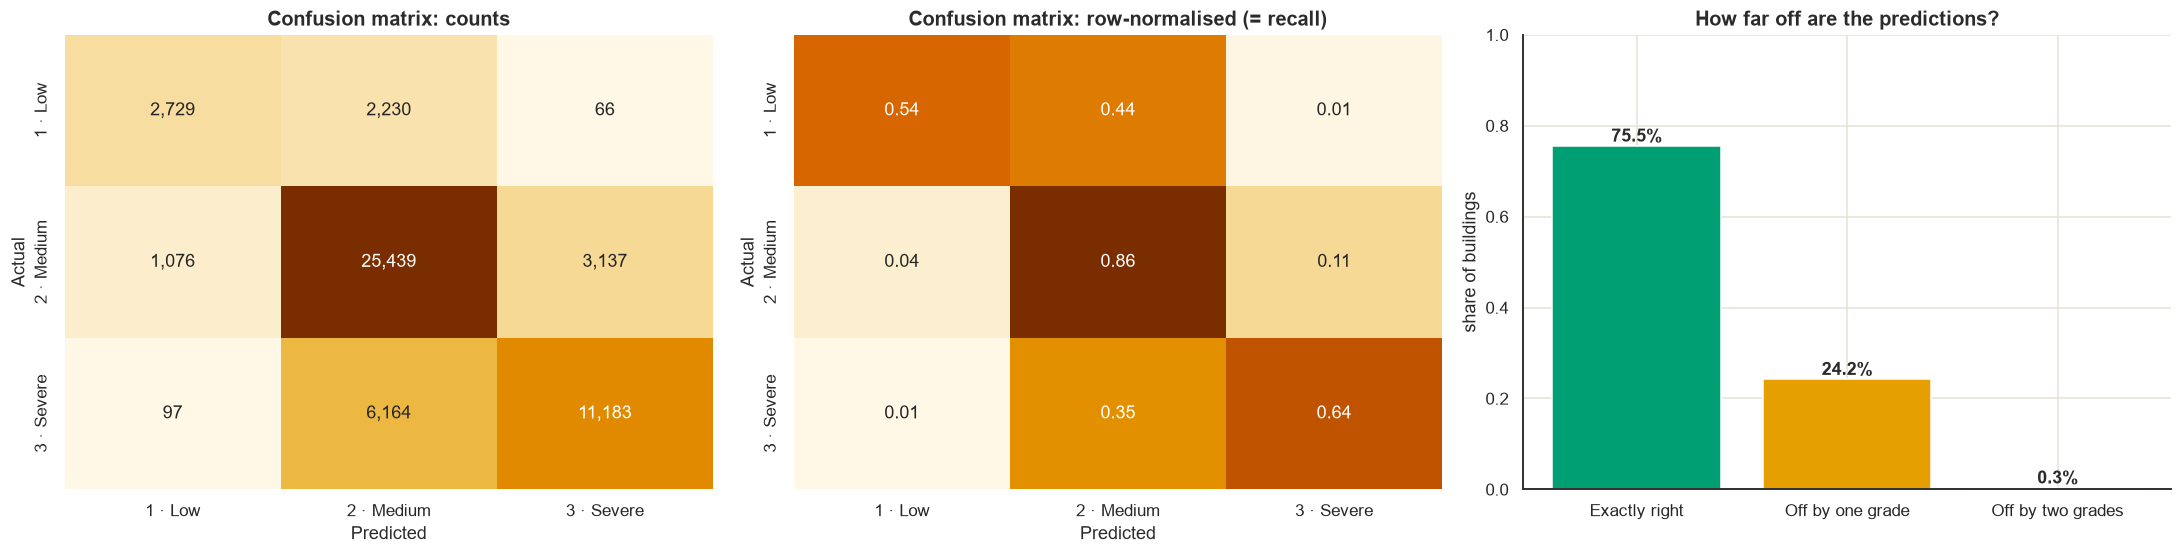

predicted,1,2,3,All
actual,,,,
1,2729,2230,66,5025
2,1076,25439,3137,29652
3,97,6164,11183,17444
All,3902,33833,14386,52121


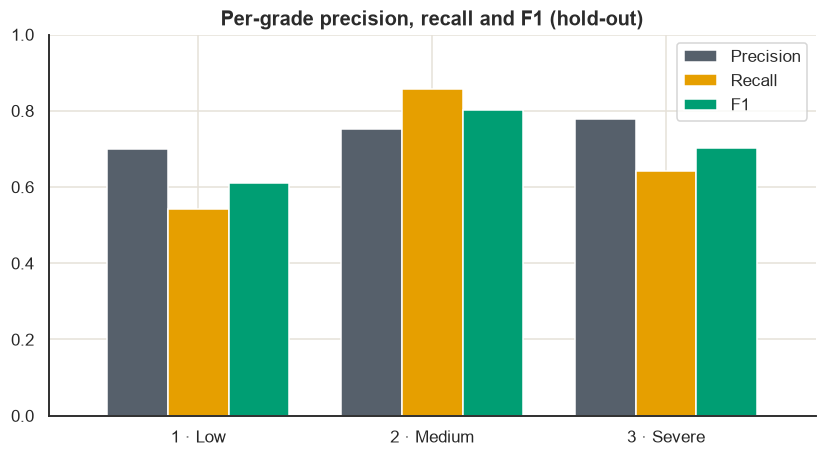

In [28]:
# (3) confusion matrices + (4) size of the mistakes
cm = confusion_matrix(y_hold, pred_hold)
labels = [GRADE_NAMES[g] for g in (1, 2, 3)]
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
sns.heatmap(cm, annot=True, fmt=",", cmap=RISK_CMAP, xticklabels=labels, yticklabels=labels, ax=axes[0], cbar=False)
axes[0].set(title="Confusion matrix: counts", xlabel="Predicted", ylabel="Actual")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap=RISK_CMAP, xticklabels=labels, yticklabels=labels, ax=axes[1], cbar=False)
axes[1].set(title="Confusion matrix: row-normalised (= recall)", xlabel="Predicted", ylabel="Actual")
gap = np.abs(y_hold - pred_hold)
shares = pd.Series({"Exactly right": (gap == 0).mean(), "Off by one grade": (gap == 1).mean(), "Off by two grades": (gap == 2).mean()})
axes[2].bar(shares.index, shares.values, color=[PALETTE[0], PALETTE[1], PALETTE[2]])
for i, v in enumerate(shares.values): axes[2].text(i, v + 0.01, f"{v:.1%}", ha="center", fontweight="bold")
axes[2].set(title="How far off are the predictions?", ylabel="share of buildings", ylim=(0, 1))
plt.tight_layout(); plt.show()

# actual vs predicted table (counts)
ct = pd.crosstab(pd.Series(y_hold + 1, name="actual"), pd.Series(pred_hold + 1, name="predicted"), margins=True)
display(ct)

# per-grade precision / recall / F1 chart
prf = pd.DataFrame(precision_recall_fscore_support(y_hold, pred_hold, labels=[0, 1, 2], zero_division=0)[:3],
                   index=["Precision", "Recall", "F1"], columns=labels).T
ax = prf.plot(kind="bar", figsize=(9, 4.5), color=[ACCENT, PALETTE[1], PALETTE[0]], width=0.78)
ax.set(title="Per-grade precision, recall and F1 (hold-out)", ylim=(0, 1)); plt.xticks(rotation=0); plt.show()

### Where do the mistakes happen?
**What:** three views of the errors: the confusion matrix (counts), the same matrix as percentages per true grade (that diagonal is the recall), and the share of buildings that are exactly right, off by one grade, or off by two.
**Why:** a single accuracy number hides *which* mistakes the model makes. In a disaster setting, calling a collapsing building "low damage" is far worse than confusing medium with severe.
**How to read:** the diagonal is correct. Cells next to it are one-grade errors. The corners (true severe → predicted low, or the reverse) are the serious errors, and these should be tiny.

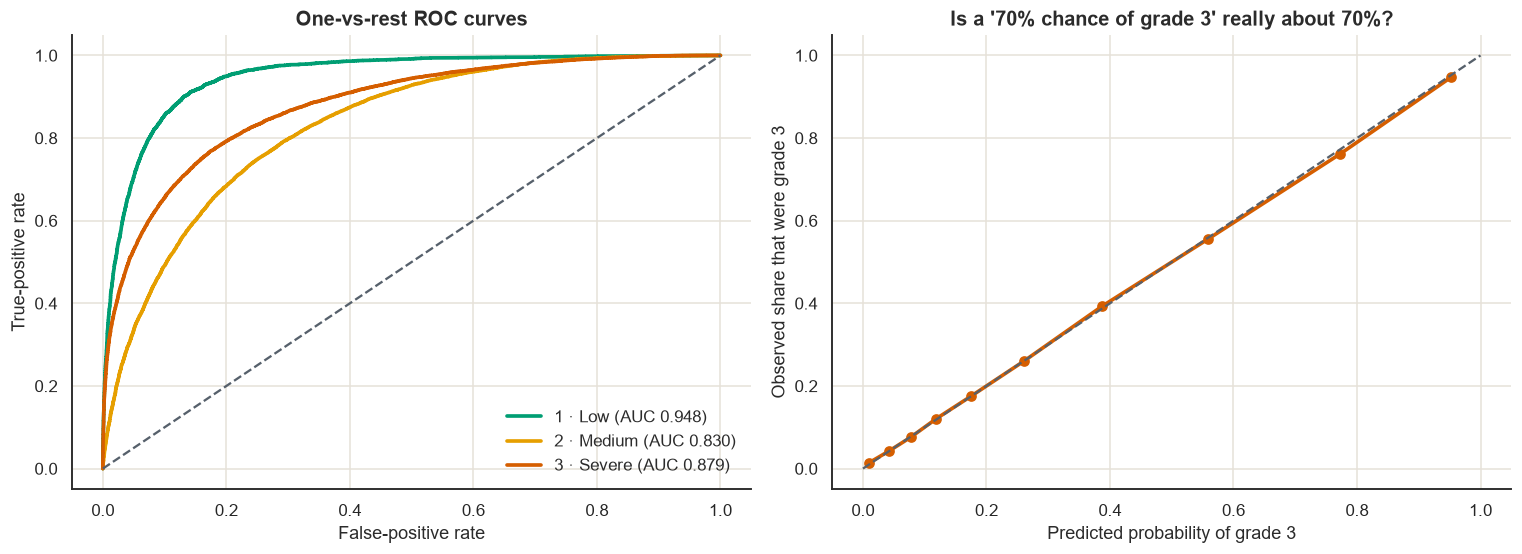

In [29]:
# (5) probability quality: ROC per grade + reliability of the grade-3 probability
from sklearn.metrics import roc_curve
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for k, g in enumerate((1, 2, 3)):
    fpr, tpr, _ = roc_curve((y_hold == k).astype(int), P_hold[:, k]); auc = roc_auc_score((y_hold == k).astype(int), P_hold[:, k])
    axes[0].plot(fpr, tpr, color=DAMAGE_COLORS[g], lw=2.4, label=f"{GRADE_NAMES[g]} (AUC {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color=ACCENT); axes[0].legend(frameon=False)
axes[0].set(title="One-vs-rest ROC curves", xlabel="False-positive rate", ylabel="True-positive rate")
frac, mean_p = calibration_curve((y_hold == 2).astype(int), P_hold[:, 2], n_bins=10, strategy="quantile")
axes[1].plot(mean_p, frac, "o-", color=DAMAGE_COLORS[3], lw=2.4); axes[1].plot([0, 1], [0, 1], "--", color=ACCENT)
axes[1].set(title="Is a '70% chance of grade 3' really about 70%?", xlabel="Predicted probability of grade 3", ylabel="Observed share that were grade 3")
plt.tight_layout(); plt.show()

### Can we trust the probabilities?
**What:** a ROC curve per grade, and a reliability (calibration) curve for the grade-3 probability.
**Why:** the government will see probabilities and tiers, not just grades. A "70% chance of collapse" is only useful if it really means about 70%.
**How to read:**
- **ROC curves:** the further they bow towards the top-left, the better the model ranks buildings of that grade. The area under the curve (AUC) summarises this, and 0.5 means no skill.
- **Reliability curve:** points on the dashed diagonal mean the predicted probability matches the observed rate. Points below it mean the model is over-confident, and points above it mean under-confident.

## Q9.1 How to read the verdict
| Measure | Result | What it means |
|---|---|---|
| **Hold-out micro-F1** | **0.755** | 75.5% of 52,121 unseen buildings were graded exactly right, against 56.9% for "always grade 2". |
| Cross-validation micro-F1 | 0.750 ± 0.002 | Matches the hold-out, so the model **generalises** and is not overfitted. |
| QWK / MAE | 0.629 / 0.248 grades | On average a prediction is about a quarter of a grade away from the truth. |
| ROC-AUC (average) | 0.886 | The model ranks risk well. |
| **Grade-3 recall** | **64.1%** (precision 77.7%) | It finds about two in three collapsing buildings, and 78% of the buildings it calls severe really are. |
| Grade-1 recall | 54.3% (precision 69.9%) | The weakest class, which is also the smallest. |
| **Severe → low** | **0.6%** | Collapsing buildings are almost never called "low damage". |

**Why not higher?** About 75–76% is the practical ceiling for this data. There are no measurements of ground shaking, soil or construction quality, and the grades are visual surveyor judgements, so the boundary between medium and severe is blurry. Most remaining errors are one-grade errors.

# Chapter 10 · What drives the predictions?
**What:** measure how much each feature matters, then group features into physical families.
**Why:** a model that predicts well for the wrong reasons is risky. If the main drivers match engineering knowledge (location, materials, height, configuration), we can trust it more.
**How the code works:** **permutation importance** shuffles one feature's values on the hold-out and measures how much accuracy drops. A large drop means the model leans on that feature. `feature_family()` then sums the drops into groups such as *Location*, *Materials*, *Geometry*, *Site* and *Age*.
**Caveat:** correlated features share credit, so family totals are approximate and should be read as a ranking, not exact percentages.

Permutation importance done in 192s


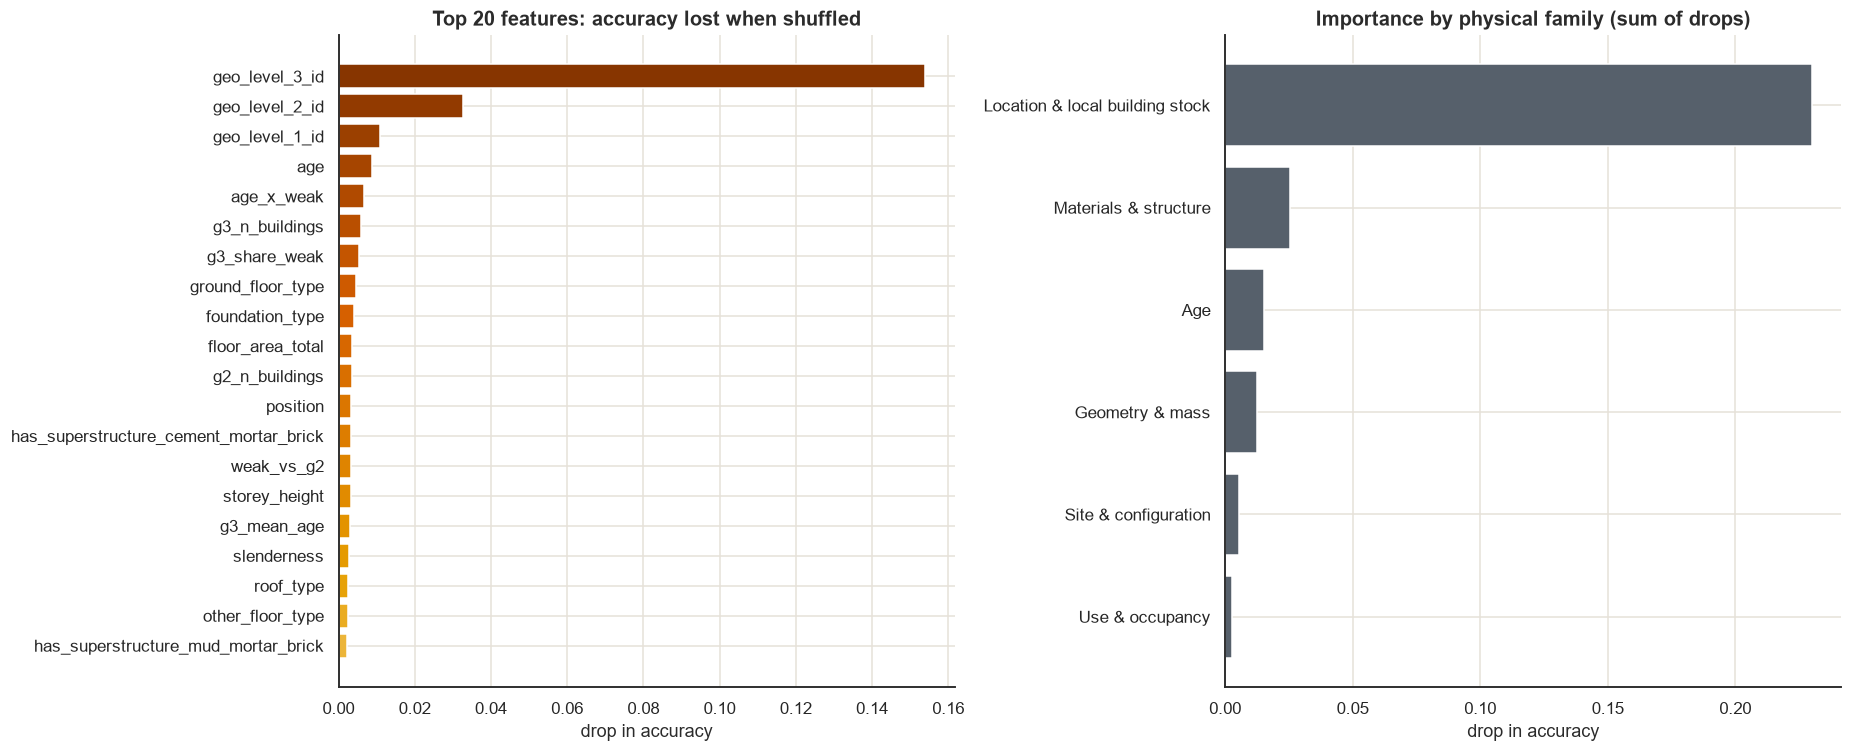

In [30]:
def feature_family(c):
    if c.startswith(("geo_", "te_", "g2_", "g3_")) or c in ("height_vs_g2", "weak_vs_g2"): return "Location & local building stock"
    if c.startswith("has_secondary") or c in ("n_secondary_use", "count_families", "no_family_recorded"): return "Use & occupancy"
    if c.startswith("age"): return "Age"
    if c in ("count_floors_pre_eq", "height_percentage", "area_percentage", "storey_height", "slenderness", "floor_area_total"): return "Geometry & mass"
    if c in ("land_surface_condition", "steep_site", "position", "attached", "plan_configuration", "irregular_plan"): return "Site & configuration"
    return "Materials & structure"

def perm_importance(model, X, y, n_repeats=3, n_rows=8000, seed=SEED):
    rs = np.random.RandomState(seed); take = rs.choice(len(X), min(n_rows, len(X)), replace=False)
    Xs, ys = X.iloc[take].reset_index(drop=True), y[take]
    base = (model.predict(Xs) == ys).mean(); out = {}
    for c in FEATURES:
        drops = []
        for _ in range(n_repeats):
            Xp = Xs.copy(); Xp[c] = rs.permutation(Xp[c].values); drops.append(base - (model.predict(Xp) == ys).mean())
        out[c] = np.mean(drops)
    return pd.Series(out).sort_values(ascending=False)

t0 = time.time(); imp = perm_importance(final_model, Xh, y_hold); print(f"Permutation importance done in {time.time() - t0:,.0f}s")
fam = imp.groupby(imp.index.map(feature_family)).sum().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
top = imp.head(20).iloc[::-1]
axes[0].barh(top.index, top.values, color=RISK_CMAP(np.linspace(0.25, 0.95, len(top))))
axes[0].set(title="Top 20 features: accuracy lost when shuffled", xlabel="drop in accuracy")
axes[1].barh(fam.index, fam.values, color=ACCENT)
axes[1].set(title="Importance by physical family (sum of drops)", xlabel="drop in accuracy")
plt.tight_layout(); plt.show()

## Q10.1 The engineering reading
Match what the chart shows to the physics we set out in Chapter 2. Location and local building stock stand in for **ground-shaking intensity and site effects**. Materials, geometry and mass describe **the structure's strength, stiffness and inertia**. Site and configuration capture **irregularity, pounding and slope amplification**. If the top features agree with those ideas, the model has learned something physically sensible, not just a statistical artefact. That is what makes it safe to hand to an engineering team.

*Note:* family totals are approximate because correlated features share credit.

# Chapter 11 · The deliverable: building IDs for the government
**What:** for every scored building, the predicted grade, the probability of each grade, and a **risk tier** based on the probability of grade 3.
**Why tiers, not just grades:** a single predicted grade hides how sure the model is. Tiers rank buildings by risk and let the government decide where to draw the line given its inspection capacity.

| Tier | P(grade 3) | Suggested action |
|---|---|---|
| **Tier 1 · Critical** | ≥ 60% | Inspect or restrict occupancy first |
| **Tier 2 · High** | 40–60% | Detailed structural assessment |
| **Tier 3 · Elevated** | 20–40% | Screening and retrofit planning |
| **Tier 4 · Lower** | < 20% | Routine monitoring |

**Before trusting the tiers we validate them** on the hold-out (next cell): among buildings placed in each tier, what share really reached grade 3?

> ⚠️ **Scope:** the model estimates how buildings with these characteristics performed in the 2015 Gorkha event. It supports inspection and retrofit *prioritisation*. It is not a forecast of a future earthquake and not a replacement for a structural engineer's assessment.

,buildings,actual_grade3_pct,actual_grade1_pct,share_of_buildings_pct
tier,,,,
Tier 1 · Critical,11854,82.500,0.300,22.700
Tier 2 · High,5876,50.000,0.800,11.300
Tier 3 · Elevated,9052,29.100,2.500,17.400
Tier 4 · Lower,25339,8.300,18.600,48.600


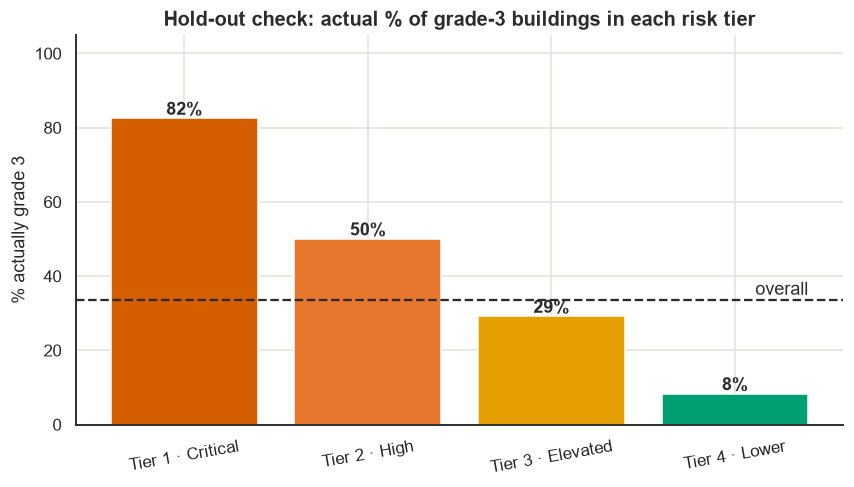

In [31]:
TIER_BINS   = [0, 0.20, 0.40, 0.60, 1.0001]
TIER_LABELS = ["Tier 4 · Lower", "Tier 3 · Elevated", "Tier 2 · High", "Tier 1 · Critical"]
def assign_tier(p3): return pd.cut(p3, bins=TIER_BINS, labels=TIER_LABELS, right=False)

# Report card on the hold-out: do the tiers mean what they say?
val = pd.DataFrame({"tier": assign_tier(P_hold[:, 2]), "actual": y_hold + 1})
report = (val.groupby("tier", observed=True).agg(buildings=("actual", "size"),
                                                 actual_grade3_pct=("actual", lambda s: (s == 3).mean() * 100),
                                                 actual_grade1_pct=("actual", lambda s: (s == 1).mean() * 100))
             .reindex(TIER_LABELS[::-1]))
report["share_of_buildings_pct"] = report["buildings"] / report["buildings"].sum() * 100
display(report.round(1))

fig, ax = plt.subplots(figsize=(9, 4.6))
colors = [PALETTE[2], "#E8772E", PALETTE[1], PALETTE[0]]
ax.bar(report.index, report["actual_grade3_pct"], color=colors)
for i, v in enumerate(report["actual_grade3_pct"]): ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontweight="bold")
ax.axhline((y_hold == 2).mean() * 100, ls="--", color=INK); ax.text(3.4, (y_hold == 2).mean() * 100 + 1.5, "overall", ha="right")
ax.set(title="Hold-out check: actual % of grade-3 buildings in each risk tier", ylabel="% actually grade 3", ylim=(0, 105))
plt.xticks(rotation=10); plt.show()

## Q11.1 Do the tiers mean what they say?
| Tier | Buildings | Share | **Actually grade 3** |
|---|---|---|---|
| Tier 1 · Critical | 11,854 | 22.7% | **82.5%** |
| Tier 2 · High | 5,876 | 11.3% | **50.0%** |
| Tier 3 · Elevated | 9,052 | 17.4% | **29.1%** |
| Tier 4 · Lower | 25,339 | 48.6% | **8.3%** (and 18.6% were grade 1) |

The tiers are **well ordered**. The share of real collapses falls steadily from 82.5% to 8.3%, against an overall rate of 33.5%. The tier labels are trustworthy as a ranking.

**What it means in practice (approximate, from the rounded table):** inspecting Tiers 1 and 2 (34% of buildings) reaches about 73% of all grade-3 buildings, and adding Tier 3 (51% of buildings) reaches about 88%. **Tier 4 still contains around 12% of grade-3 buildings**, so "lower risk" is not "safe", and the government should keep a monitoring plan for it.

In [32]:
# Score the buildings the government cares about
if test_clean is not None:
    # refit on ALL labelled buildings (dev + hold-out), then score the unseen survey file
    final_all = WeightedEnsemble([clone(p) for p in final_model.pipes], final_model.weights)
    final_all.fit(pd.concat([Xd, Xh], ignore_index=True), np.concatenate([y_dev, y_hold]))
    score_X, scorer, source = make_features(test_clean), final_all, "test_values.csv (unseen buildings)"
else:
    score_X, scorer, source = X_hold, final_model, "the 20% hold-out buildings (no test_values.csv found)"
print("Scoring:", source, "·", f"{len(score_X):,} buildings")

P = scorer.predict_proba(score_X[FEATURES]); pred = scorer.predict(score_X[FEATURES]) + 1
result = pd.DataFrame({
    "building_id":        score_X[ID].values,
    "predicted_grade":    pred,
    "predicted_label":    pd.Series(pred).map({1: "Low damage", 2: "Medium damage", 3: "Severe / near-complete destruction"}),
    "prob_grade1":        P[:, 0].round(4), "prob_grade2": P[:, 1].round(4), "prob_grade3": P[:, 2].round(4),
    "expected_grade":     (P * np.array([1, 2, 3])).sum(axis=1).round(3),
    "risk_tier":          assign_tier(P[:, 2]).astype(str),
    "geo_level_1_id":     score_X["geo_level_1_id"].values, "geo_level_2_id": score_X["geo_level_2_id"].values,
    "geo_level_3_id":     score_X["geo_level_3_id"].values,
    "foundation":         score_X["foundation_type"].map(LABELS["foundation_type"]).values,
    "roof":               score_X["roof_type"].map(LABELS["roof_type"]).values,
    "floors":             score_X["count_floors_pre_eq"].values, "age_years": score_X["age"].values,
    "weak_masonry":       score_X["weak_masonry"].values})
result = result.sort_values("prob_grade3", ascending=False).reset_index(drop=True)
result["priority_rank"] = np.arange(1, len(result) + 1)

# ---- files for the government ----
result.to_csv(OUT_DIR / "building_damage_predictions_all.csv", index=False)
result[result["predicted_grade"] == 3].to_csv(OUT_DIR / "priority_inspection_list_grade3.csv", index=False)
result[result["risk_tier"] == "Tier 1 · Critical"].to_csv(OUT_DIR / "tier1_critical_buildings.csv", index=False)
for g in (1, 2):
    result[result["predicted_grade"] == g][["building_id", "predicted_grade", "prob_grade1", "prob_grade2", "prob_grade3", "risk_tier"]] \
        .to_csv(OUT_DIR / f"predicted_grade{g}_ids.csv", index=False)
if test_clean is not None:   # competition-format submission
    result[["building_id", "predicted_grade"]].rename(columns={"predicted_grade": "damage_grade"}).sort_values("building_id") \
          .to_csv(OUT_DIR / "submission.csv", index=False)

summary = pd.DataFrame({"buildings": result["predicted_grade"].value_counts().sort_index(),
                        "share_%": result["predicted_grade"].value_counts(normalize=True).sort_index() * 100})
summary.index = [GRADE_NAMES[g] for g in summary.index]
display(summary.round(1))
print("\nTier counts:"); display(result["risk_tier"].value_counts().reindex(TIER_LABELS[::-1]).to_frame("buildings"))
print("\nTop 15 buildings by probability of near-complete destruction:")
display(result.head(15)[["priority_rank", "building_id", "predicted_grade", "prob_grade3", "risk_tier", "geo_level_1_id", "geo_level_2_id", "foundation", "roof", "floors", "age_years"]])
print("Files saved in:", OUT_DIR.resolve())

Scoring: the 20% hold-out buildings (no test_values.csv found) · 52,121 buildings


,buildings,share_%
1 · Low,3902,7.500
2 · Medium,33833,64.900
3 · Severe,14386,27.600



Tier counts:


,buildings
risk_tier,
Tier 1 · Critical,11854
Tier 2 · High,5876
Tier 3 · Elevated,9052
Tier 4 · Lower,25339



Top 15 buildings by probability of near-complete destruction:


,priority_rank,building_id,predicted_grade,prob_grade3,risk_tier,geo_level_1_id,geo_level_2_id,foundation,roof,floors,age_years
0,1,998786,3,0.998,Tier 1 · Critical,17,648,Mud mortar stone/brick,Heavy roof (bamboo/timber),1,10.000
1,2,665433,3,0.998,Tier 1 · Critical,17,648,Mud mortar stone/brick,Heavy roof (bamboo/timber),1,10.000
2,3,170270,3,0.998,Tier 1 · Critical,17,1183,Mud mortar stone/brick,Light roof (bamboo/timber),2,40.000
3,4,1022483,3,0.998,Tier 1 · Critical,17,1183,Mud mortar stone/brick,Light roof (bamboo/timber),2,35.000
4,5,453618,3,0.998,Tier 1 · Critical,17,648,Mud mortar stone/brick,Heavy roof (bamboo/timber),1,15.000
5,6,95489,3,0.998,Tier 1 · Critical,17,648,Mud mortar stone/brick,Heavy roof (bamboo/timber),1,25.000
6,7,171394,3,0.998,Tier 1 · Critical,17,1149,Mud mortar stone/brick,Light roof (bamboo/timber),3,25.000
7,8,913886,3,0.998,Tier 1 · Critical,17,817,Mud mortar stone/brick,Heavy roof (bamboo/timber),3,40.000
8,9,459158,3,0.998,Tier 1 · Critical,17,817,Mud mortar stone/brick,Heavy roof (bamboo/timber),3,20.000
9,10,476885,3,0.998,Tier 1 · Critical,17,1183,Mud mortar stone/brick,Light roof (bamboo/timber),2,15.000


Files saved in: C:\Users\kanap\outputs


### Producing the lists
**What:** score the buildings, attach probabilities and tiers, rank them, and save CSV files.
**Why:** the output has to be usable by people who will never open this notebook: plain IDs, ranked by priority, in files they can filter.
**How the code works:** the model predicts probabilities, `assign_tier()` converts the grade-3 probability into a tier, buildings are sorted by that probability (`priority_rank = 1` is the most at risk), and readable foundation and roof descriptions are attached for context. Separate files are written for each category.

**Important:** this run found no `test_values.csv`, so the lists were built from the **52,121 hold-out buildings**. These are the buildings the model never trained on, so they are fair examples, but they are not the full national set. To score a new batch of buildings, put its `test_values.csv` in the data folder and re-run this cell: it then retrains on all labelled buildings and scores the new file.

### Where should teams go first?
**What:** summarise predicted risk by district, and chart the 15 highest-risk districts and the predicted grade counts.
**Why:** the government deploys teams to areas, not to individual buildings, so district-level hotspots help plan resources.
**How the code works:** buildings are grouped by region and district, and for each group we compute the number of buildings, the average probability of grade 3, and the number in Tier 1. Districts with too few buildings are excluded because their averages are unreliable.

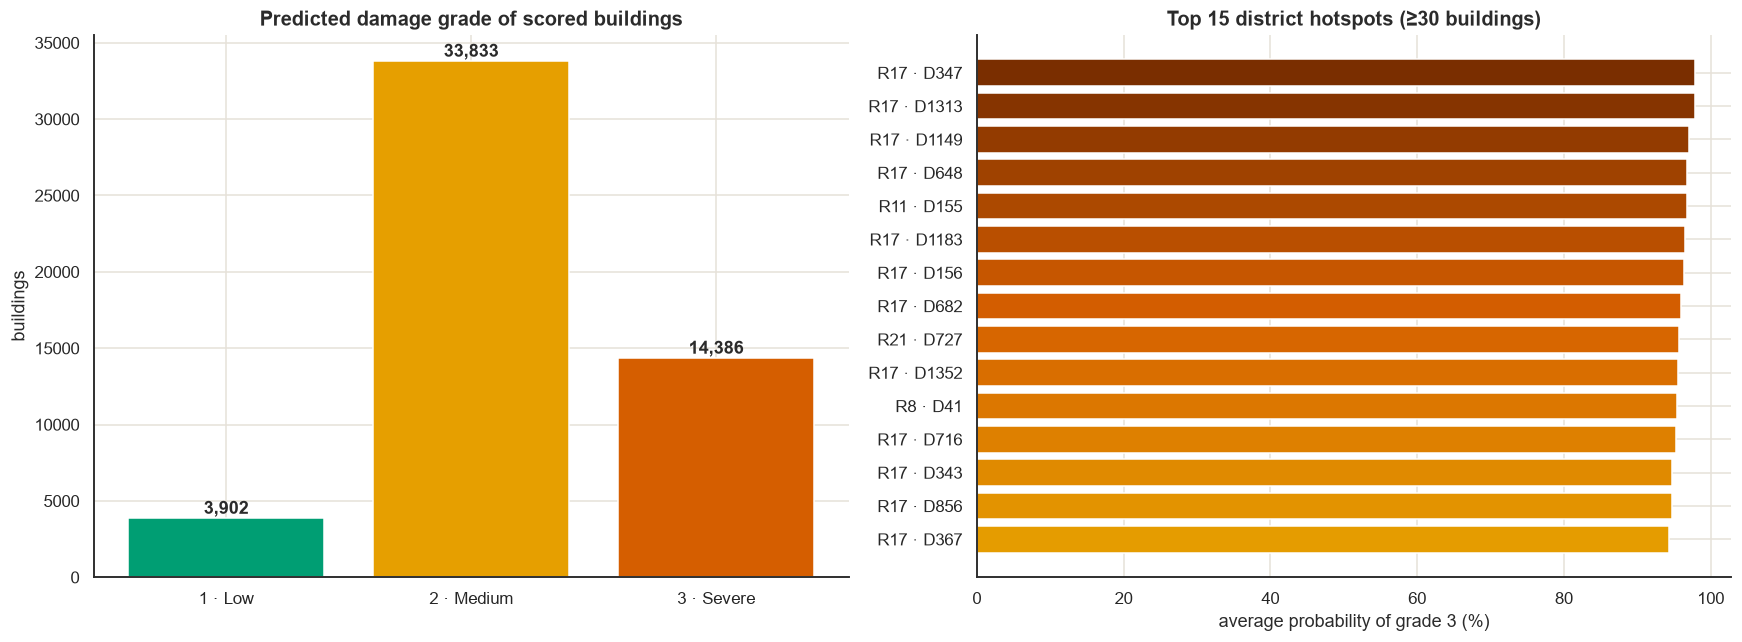

In [33]:
# Where should teams go first? District-level hotspots of predicted severe damage
hot = (result.groupby(["geo_level_1_id", "geo_level_2_id"])
             .agg(buildings=("building_id", "size"), mean_prob_grade3=("prob_grade3", "mean"),
                  tier1_critical=("risk_tier", lambda s: (s == "Tier 1 · Critical").sum()),
                  expected_grade=("expected_grade", "mean")).reset_index())
min_n = 10 if QUICK_MODE else 30
hot = hot[hot["buildings"] >= min_n].sort_values("mean_prob_grade3", ascending=False)
hot.to_csv(OUT_DIR / "district_hotspots.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(summary.index, summary["buildings"], color=PALETTE)
for i, v in enumerate(summary["buildings"]): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontweight="bold")
axes[0].set(title="Predicted damage grade of scored buildings", ylabel="buildings")
t15 = hot.head(15).iloc[::-1]
axes[1].barh([f"R{a} · D{b}" for a, b in zip(t15["geo_level_1_id"], t15["geo_level_2_id"])], t15["mean_prob_grade3"] * 100,
             color=RISK_CMAP(np.linspace(0.35, 1, len(t15))))
axes[1].set(title=f"Top 15 district hotspots (≥{min_n} buildings)", xlabel="average probability of grade 3 (%)")
plt.tight_layout(); plt.show()

# Conclusions and next steps

**What we built:** a reproducible pipeline: audit → exploration → locked hold-out → physics-based features → leak-proof pipeline → ordinal-aware model comparison → tuning → honest verdict → ranked deliverable.

**Key results (52,121 unseen buildings)**
- **75.5% exact-grade accuracy** (baseline 56.9%), matching cross-validation (75.0%).
- **81.8% accuracy for "severe vs not severe"** (baseline 66.5%).
- Collapsing buildings are called "low damage" only **0.6%** of the time.
- Risk tiers are well ordered: **82.5% of Tier 1 buildings really were grade 3**, against 8.3% in Tier 4.

**Why we did what we did:** see the "How the prediction model works" explanation below.

**Limits**
- Labels come from one earthquake, and shaking intensity was not measured, so location stands in for it.
- The obfuscated category meanings come from secondary sources and should be checked against the official codebook.
- Tiers are statistical triage, not engineering verdicts.

**Next steps:** add LightGBM or CatBoost as extra blend members, add a parent-district fallback for rare villages, and average several random seeds.

# How the prediction model works, in plain language

## 1 · The question it answers
Given a building's **location**, **structure**, **size**, **age** and **use**, the model estimates the probability that the 2015 earthquake left it with *low*, *medium* or *severe* damage. It then picks the most likely grade and ranks buildings by their probability of severe damage.

## 2 · What it looks at
Four groups of information:
- **Where:** region, district and village. Location stands in for how hard the ground shook and how soft the soil was, which we could not measure directly.
- **How it was built:** foundation, roof, floors, wall materials.
- **Shape and size:** number of floors, height, footprint, plan shape, whether it touches neighbours.
- **Age and use:** age (when known) and whether it had a second use.

We also gave it engineering-style features, such as how tall and narrow a building is and whether a heavy roof sits on weak walls.

## 3 · How it learns
The model is a **gradient-boosted decision-tree ensemble**. Think of a panel of hundreds of small decision trees, each asking simple questions such as *"mud-mortar walls? heavy roof? more than two floors?"*. The trees are added one at a time, and each new tree concentrates on the buildings the earlier trees got wrong. The final prediction is the combined vote of the whole panel.

## 4 · Two models, blended
- **Model A** looks at all three grades at once.
- **Model B** respects the *order* of the grades. It asks two yes/no questions: *"Is this building at least medium damage?"* and *"Is it severe?"*, then combines the answers.
- The final model **averages A and B**. Their different views of the problem make the answer a little steadier.

## 5 · How it handles location
Districts and villages are too many (1,414 and 11,595) to treat as simple categories, and their ID numbers have no order. For each location the model uses its **historic damage rate**, calculated carefully so that a building never "sees" its own result when the rate is computed, and smoothed so that a village with few buildings cannot mislead the model.

## 6 · From probabilities to decisions
For each building the model produces three probabilities that add to 100%, for example *5% low, 25% medium, 70% severe*.
- The **predicted grade** is the most likely one (after a small rebalancing).
- The **risk tier** is based on the probability of severe damage alone: Tier 1 (≥60%), Tier 2 (40–60%), Tier 3 (20–40%), Tier 4 (<20%).

## 7 · How accurate is it?
On 52,121 buildings the model had never seen:
- **About 3 in 4 are graded exactly right** (75.5%), compared with 57% for always guessing the middle grade.
- Almost all remaining mistakes are **one grade off** (for example, medium called severe).
- It almost never calls a collapsing building "low damage" (**0.6%**).
- For "will this building be severely damaged?" it is right **82%** of the time (baseline 66.5%).
- **Tier 1 buildings were severely damaged 82.5% of the time**, against 8.3% for Tier 4.

## 8 · How the government should use it
1. **Inspect in tier order**, starting with Tier 1, using `priority_rank` within each tier.
2. **Send teams to hotspot districts** (`district_hotspots.csv`) where many Tier 1 buildings cluster.
3. **Do not treat Tier 4 as safe.** About 8% of Tier 4 buildings were severely damaged, so keep a monitoring plan.
4. **Where the model is unsure** (probabilities spread across grades), send the building for manual engineer review.

## 9 · What it cannot do
- It reflects **one earthquake** and cannot predict a future one of different size or location.
- It had **no measurements of ground shaking, soil, or construction quality**, so it cannot separate two buildings that look identical on paper.
- The survey grades are **visual judgements**, so the line between "medium" and "severe" is blurry.
- It is a **prioritisation tool**, not a structural assessment, and it does not replace an engineer's inspection.

## 10 · Decision log: why we did what we did
| Decision | Why | Evidence |
|---|---|---|
| Set age 995 and 200 to missing, add a flag | They are placeholders, not real ages | 1,496 buildings |
| No resampling of classes | Micro-F1 is measured on the natural mix, and no class is tiny | Grades are 9.6 / 56.9 / 33.5% |
| Locked 20% hold-out | Gives an honest final score | CV 0.750 vs hold-out 0.755 |
| Target encoding done inside the pipeline | Prevents label leakage into cross-validation | Hold-out matches CV |
| Added physics-based features | Raw columns don't state engineering relationships | Test cells in Chapter 4 |
| Compared ordinal and plain models | The target is ordered | Ordinal C has the best QWK and grade-3 recall |
| Many metrics, not just accuracy | Accuracy hides which mistakes matter | Severe→low only 0.6% |
| Blended A and B | Slightly more stable, never worse | 0.750 vs 0.749 |
| Picked faster tuning settings | Equal accuracy, half the training time | Top 5 settings within 0.001 |
| Risk tiers on the grade-3 probability | Lets the government choose its own cut-off | 82.5% → 8.3% across tiers |
| Reported baselines next to every score | Prevents misleading numbers | "Within one grade" is 100% for a naive model |